<a href="https://colab.research.google.com/github/Riddhi-sss/ISL-Recognition/blob/main/ISL_iSign_CrossDataset_Methodology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pose-Based Indian Sign Language Recognition Using Deep Learning on the iSign Dataset

**Reproducible Google Colab notebook — revised methodology**

## Research design

This notebook separates the work into two distinct stages:

1. **iSign representation learning:** extract and audit pose sequences, then train a temporal Transformer using self-supervised contrastive learning on unlabelled iSign pose clips.
2. **Cross-dataset isolated-sign recognition:** transfer the frozen iSign-pretrained encoder to the CISLR one-shot recognition task. CISLR's official prototype clips are references; its query clips are evaluated using Top-1, Top-5 and Top-10 retrieval.

The iSign word recordings are not used for conventional supervised multi-class training because almost every word label has only one recording. The iSign metadata also does not contain word start/end timestamps. Motion-activity segmentation is therefore exploratory and is **not** evaluated as semantic word-boundary detection.

### Important interpretation

- iSign is the self-supervised pretraining dataset.
- CISLR is the labelled recognition-evaluation dataset.
- A successful CISLR result demonstrates cross-dataset transfer, not supervised recognition accuracy on iSign.
- The previously explored CISLR test set is not a pristine blind test. The held-back partition below is useful for consistent comparisons, but this limitation must be disclosed in the report.

## Notebook map

| Section | Contents |
|---|---|
| 0 | Runtime, paths and reproducibility |
| 1 | Load iSign metadata and pose caches |
| 2 | Dataset diagnostics: word labels, missing clips, lengths and sentence links |
| 3 | Landmark visibility and motion diagnostics |
| 4 | Pose features and augmentations |
| 5 | iSign-only self-supervised Transformer pretraining |
| 6 | Load CISLR metadata and pose cache |
| 7 | Source-independent CISLR evaluation split |
| 8 | Handcrafted baseline and iSign-pretrained recognition |
| 9 | CISLR-only contrastive control and optional ST-GCN |
| 10 | Optional DTW reranking and model comparison |
| 11 | Exploratory motion-activity segmentation |
| 12 | Save outputs and report checklist |

**Run from top to bottom.** Use a Colab GPU runtime for deep-learning experiments. The notebook expects the existing Drive cache folders created during the earlier project work.

## 0. Runtime and configuration

The default paths match the current project structure:

- Project folder: `/content/drive/MyDrive/isl_project`
- iSign pose cache: `wordpres/` and `cache/`
- Original iSign metadata: `isign/iSign_v1.1.csv`
- Word-presence metadata: `/content/drive/MyDrive/word-presence-dataset_v1.1.csv`
- CISLR pose cache: `cislr_task3/`

If your folders are stored elsewhere, change the paths in the next cell.

In [1]:
!pip -q install huggingface_hub scipy scikit-learn ruptures

import os, re, json, time, random, zipfile, urllib.request, warnings, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks
from sklearn.model_selection import GroupShuffleSplit
from huggingface_hub import snapshot_download

import torch
import torch.nn as nn
import torch.nn.functional as F

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

ROOT = Path("/content/drive/MyDrive/isl_project")
ISIGN_CACHE_DIRS = [ROOT / "wordpres", ROOT / "cache"]
ISIGN_META_PATH = ROOT / "isign" / "iSign_v1.1.csv"
WORD_PRESENCE_PATH = Path("/content/drive/MyDrive/word-presence-dataset_v1.1.csv")

CIS_ROOT = Path("/content/cislr")
CIS_CACHE = ROOT / "cislr_task3"
OUTPUT_DIR = ROOT / "final_methodology_outputs"

for p in [ROOT, CIS_ROOT, CIS_CACHE, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

N_FRAMES = 32
FEATURE_DIM = 102
BATCH_SIZE = 128
PRETRAIN_EPOCHS = 60
LEARNING_RATE = 3e-4
TEMPERATURE = 0.1
RUN_CISLR_CONTROL = True
RUN_STGCN = False
RUN_DTW = False

print("Project:", ROOT)
print("iSign metadata exists:", ISIGN_META_PATH.exists())
print("Word-presence CSV exists:", WORD_PRESENCE_PATH.exists())
print("CISLR cache:", CIS_CACHE)

Mounted at /content/drive
Device: cuda
Project: /content/drive/MyDrive/isl_project
iSign metadata exists: True
Word-presence CSV exists: False
CISLR cache: /content/drive/MyDrive/isl_project/cislr_task3


## 1. Load iSign metadata and pose caches

The original iSign metadata contains `uid` and `text`. It does not contain word-level start/end timestamps. The cache is loaded from both existing cache folders, with duplicate IDs counted and resolved deterministically.

In [5]:
isign_clips = {}
cache_file_count = 0

for cache_dir in ISIGN_CACHE_DIRS:
    files = sorted(cache_dir.glob("chunk_*.npz"))
    print(cache_dir, "| chunk files:", len(files))

    for cache_file in files:
        cache_file_count += 1

        with np.load(cache_file) as z:
            for uid in z.files:
                arr = z[uid].astype(np.float32)

                if arr.ndim != 3 or arr.shape[1] != 49:
                    continue

                if arr.shape[2] == 2:
                    isign_clips[uid] = arr

print("2D pose clips loaded:", len(isign_clips))
print("Cache chunks read:", cache_file_count)

matched_ids = set(isign_meta["uid"]) & set(isign_clips)
print("Metadata IDs with 2D poses:", len(matched_ids))

/content/drive/MyDrive/isl_project/wordpres | chunk files: 42
/content/drive/MyDrive/isl_project/cache | chunk files: 10
2D pose clips loaded: 2053
Cache chunks read: 52
Metadata IDs with 2D poses: 2053


In [6]:
assert all(
    arr.ndim == 3 and arr.shape[1:] == (49, 2)
    for arr in isign_clips.values()
)

print("All loaded clips have the expected (T, 49, 2) format.")

All loaded clips have the expected (T, 49, 2) format.


In [7]:
from collections import Counter

word_ids = set()
sentence_ids = set()

if 'word-presence-dataset_v1.1.csv' in globals():
    wp = pd.read_csv('/content/drive/MyDrive/word-presence-dataset_v1.1.csv')
    word_ids = set(wp['word_id'].astype(str))
    sentence_ids = set(wp['sentence_id'].astype(str))

loaded_ids = set(isign_clips)

word_matches = loaded_ids & word_ids
sentence_matches = loaded_ids & sentence_ids

print("Total loaded clips:", len(loaded_ids))
print("Word-level clips matched:", len(word_matches))
print("Sentence-level clips matched:", len(sentence_matches))
print("Other clips:", len(loaded_ids - word_matches - sentence_matches))

Total loaded clips: 2053
Word-level clips matched: 0
Sentence-level clips matched: 0
Other clips: 2053


In [9]:
from pathlib import Path

matches = list(
    Path('/content/drive/MyDrive').rglob('word-presence-dataset_v1.1.csv')
)

print("Files found:", len(matches))

for path in matches:
    print(path)

Files found: 1
/content/drive/MyDrive/isl_project/isign/word-presence-dataset_v1.1.csv


In [11]:
wp = pd.read_csv('/content/drive/MyDrive/isl_project/isign/word-presence-dataset_v1.1.csv')

In [12]:
word_ids = set(wp['word_id'].astype(str))
sentence_ids = set(wp['sentence_id'].astype(str))
loaded_ids = set(isign_clips)

word_matches = loaded_ids & word_ids
sentence_matches = loaded_ids & sentence_ids

print("Total loaded clips:", len(loaded_ids))
print("Word-level clips matched:", len(word_matches))
print("Sentence-level clips matched:", len(sentence_matches))
print("Other clips:", len(loaded_ids - word_matches - sentence_matches))

Total loaded clips: 2053
Word-level clips matched: 561
Sentence-level clips matched: 1492
Other clips: 0


In [13]:
isign_word_clips = {
    uid: isign_clips[uid]
    for uid in word_ids
    if uid in isign_clips
}

isign_sentence_clips = {
    uid: isign_clips[uid]
    for uid in sentence_ids
    if uid in isign_clips
}

print("Word clips:", len(isign_word_clips))
print("Sentence clips:", len(isign_sentence_clips))
print("Total:", len(isign_word_clips) + len(isign_sentence_clips))

Word clips: 561
Sentence clips: 1492
Total: 2053


In [14]:
from collections import Counter

for cache_dir in ISIGN_CACHE_DIRS:
    shapes = Counter()
    examples = {}

    for cache_file in sorted(cache_dir.glob("chunk_*.npz")):
        with np.load(cache_file) as z:
            for uid in z.files:
                shape = z[uid].shape
                shapes[shape[-1]] += 1
                examples.setdefault(shape[-1], uid)

    print("\nCache directory:", cache_dir)
    print("Coordinate-channel distribution:", dict(shapes))
    print("Examples:", examples)


Cache directory: /content/drive/MyDrive/isl_project/wordpres
Coordinate-channel distribution: {2: 2053}
Examples: {2: 'vlRgT4SgD_s_e4'}

Cache directory: /content/drive/MyDrive/isl_project/cache
Coordinate-channel distribution: {3: 1000}
Examples: {3: 'M3OUJYjZkqw--24'}


## 2. iSign dataset diagnostics

### 2.1 Isolated-word recording counts

The `_w` suffix identifies isolated-word recordings. The label is the corresponding `text` field. This check reproduces the word-recording counts and label-frequency distribution.

In [15]:
word_meta = isign_meta[
    isign_meta["uid"].str.endswith("_w")
].copy()

word_meta["label"] = word_meta["text"].str.strip().str.lower()

word_ids = set(word_meta["uid"])
word_pose = {
    uid: isign_clips[uid]
    for uid in word_ids
    if uid in isign_clips
}

print("Word metadata recordings:", len(word_meta))
print("Unique word labels:", word_meta["label"].nunique())
print("Word recordings with pose data:", len(word_pose))
print("Missing word pose recordings:", len(word_ids - set(word_pose)))

print("\nMost repeated labels:")
display(word_meta["label"].value_counts().head(20))

print("\nLabel frequency distribution:")
display(word_meta["label"].value_counts().value_counts().sort_index())

available_word_meta = word_meta[
    word_meta["uid"].isin(word_pose)
].copy()

print("\nAvailable recordings:", len(available_word_meta))
print("Unique available labels:", available_word_meta["label"].nunique())
print("Repeated labels among available recordings:")
display(
    available_word_meta["label"].value_counts()
    .loc[lambda x: x > 1]
)

missing_word_meta = word_meta[
    ~word_meta["uid"].isin(word_pose)
][["uid", "text"]].reset_index(drop=True)

print("Missing word recordings:", len(missing_word_meta))
display(missing_word_meta)

assert len(word_meta) == 586
assert len(word_pose) == 561
assert available_word_meta["label"].nunique() == 559

Word metadata recordings: 586
Unique word labels: 584
Word recordings with pose data: 561
Missing word pose recordings: 25

Most repeated labels:


,count
label,
reflect,2
agitate,2
opportunity,1
aspiring,1
elude - 2,1
reception,1
bribe,1
dissipate,1
mysterious,1



Label frequency distribution:


,count
count,
1,582
2,2



Available recordings: 561
Unique available labels: 559
Repeated labels among available recordings:


,count
label,
reflect,2
agitate,2


Missing word recordings: 25


,uid,text
0,0EaLX2t1wPU_w,rapid
1,1_DthSKKZDU_w,demonstrate
2,2am65aHTIRA_w,competent
3,5dQrlNM9QVs_w,amphibious
4,63BZd84xk-c_w,abroad
5,6VINDvdwb_E_w,sustain
6,ksOfiEDqudU_w,ambidextrous
7,LNPAwwKB-L8_w,warm
8,NHUAhGE0cMc_w,swap
9,O9p59lV3nhU_w,reassuring


### 2.2 Why supervised iSign word classification is not used

Almost every available word class has one recording. A conventional train/test split would either leave classes without training examples or require splitting frames from the same clip, which would create leakage. The isolated-word collection is therefore used for representation analysis and self-supervised learning, not a 559-class supervised accuracy claim.

,frames
count,561.000000
mean,171.224599
std,116.015283
min,13.000000
25%,116.000000
50%,145.000000
75%,180.000000
max,961.000000


Minimum frames: 13
Maximum frames: 961
Mean frames: 171.22
Clips shorter than 12 frames: 0


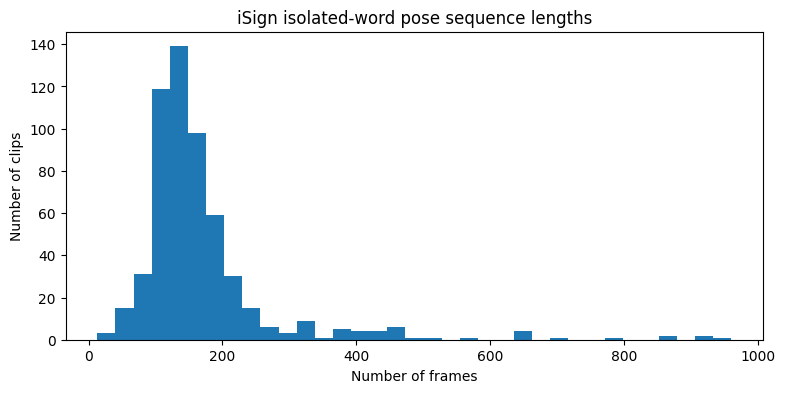

In [16]:
word_lengths = np.array([len(a) for a in word_pose.values()])

word_length_summary = pd.Series(word_lengths).describe()
display(word_length_summary.to_frame("frames"))

print("Minimum frames:", int(word_lengths.min()))
print("Maximum frames:", int(word_lengths.max()))
print("Mean frames:", round(float(word_lengths.mean()), 2))
print("Clips shorter than 12 frames:", int((word_lengths < 12).sum()))

plt.figure(figsize=(9, 4))
plt.hist(word_lengths, bins=35)
plt.title("iSign isolated-word pose sequence lengths")
plt.xlabel("Number of frames")
plt.ylabel("Number of clips")
plt.show()

### 2.3 Sentence-level clips and word-to-sentence links

Sentence clips use IDs ending in `_e1`, `_e2`, and so on. The separate word-presence CSV links a target word recording to sentence recordings, but it does not supply word start/end times. We use it only to inspect the relationship between recordings, not to infer exact temporal boundaries.

In [17]:
sentence_meta = isign_meta[
    isign_meta["uid"].str.contains(r"_e\d+$", regex=True)
].copy()

sentence_ids = set(sentence_meta["uid"])
sentence_pose_ids = sentence_ids & set(isign_clips)

print("Sentence metadata recordings:", len(sentence_meta))
print("Sentence recordings with pose data:", len(sentence_pose_ids))
print("Sentence recordings without pose data:", len(sentence_ids - sentence_pose_ids))

print("\nMetadata columns:", isign_meta.columns.tolist())
timestamp_candidates = [
    c for c in isign_meta.columns
    if any(k in c.lower() for k in ["start", "end", "time", "timestamp"])
]
print("Possible timestamp columns:", timestamp_candidates)

if WORD_PRESENCE_PATH.exists():
    word_presence = pd.read_csv(WORD_PRESENCE_PATH)
    print("\nWord-presence columns:", word_presence.columns.tolist())
    print("Word-presence shape:", word_presence.shape)
    display(word_presence.head())

    if {"word_id", "word", "sentence_id", "sentence"}.issubset(word_presence.columns):
        wp_word_ids = set(word_presence["word_id"].astype(str))
        wp_sentence_ids = set(word_presence["sentence_id"].astype(str))
        print("Unique word IDs in word-presence CSV:", len(wp_word_ids))
        print("Unique sentence IDs in word-presence CSV:", len(wp_sentence_ids))
        print("Word IDs matching pose cache:", len(wp_word_ids & set(isign_clips)))
        print("Sentence IDs matching pose cache:", len(wp_sentence_ids & set(isign_clips)))
else:
    print("Word-presence CSV not found; skip this linkage diagnostic.")

example_base = "U-c1RT4IfL8"
display(
    isign_meta[
        isign_meta["uid"].str.contains(example_base, na=False)
    ][["uid", "text"]]
)

print("Interpretation: `_w` is the isolated word; `_eN` entries are example sentences.")
print("No exact word timestamps are present in these metadata columns.")

Sentence metadata recordings: 1492
Sentence recordings with pose data: 1492
Sentence recordings without pose data: 0

Metadata columns: ['uid', 'text']
Possible timestamp columns: []
Word-presence CSV not found; skip this linkage diagnostic.


,uid,text
21283,U-c1RT4IfL8_d,feeling guilty or embarrassed about something ...
21284,U-c1RT4IfL8_e1,He was ashamed to admit to his mistake.
21285,U-c1RT4IfL8_e2,I felt deeply ashamed for my father's impolite...
21286,U-c1RT4IfL8_e3,I'm ashamed to be seen with you when you behav...
21287,U-c1RT4IfL8_e4,She was ashamed to ask her brother for money.
21288,U-c1RT4IfL8_w,ashamed


Interpretation: `_w` is the isolated word; `_eN` entries are example sentences.
No exact word timestamps are present in these metadata columns.


### 2.4 Missing-pose audit and final iSign subset

The 25 missing word recordings are retained in the audit table but excluded from pose-based experiments. Missing sequences are not replaced with artificial zeros.

In [18]:
missing_pose_audit = pd.DataFrame({
    "metadata_uid": sorted(missing_metadata_pose_ids)
})
missing_word_ids = sorted(word_ids - set(word_pose))

print("Final isolated-word pose count:", len(word_pose))
print("Final isolated-word missing count:", len(missing_word_ids))
print("Pose-cache coverage:", round(100 * len(word_pose) / len(word_ids), 2), "%")

assert len(missing_word_ids) == 25
assert len(word_pose) == 561

# The self-supervised pool contains metadata-matched iSign pose clips
# (both isolated-word and sentence clips), with at least 12 frames.
isign_train_ids = sorted(
    uid for uid in matched_ids
    if len(isign_clips[uid]) >= 12
)
isign_train_clips = [isign_clips[uid] for uid in isign_train_ids]

print("iSign clips selected for self-supervised learning:", len(isign_train_clips))
print("Word clips in pool:", sum(uid.endswith("_w") for uid in isign_train_ids))
print("Sentence clips in pool:", sum(bool(re.search(r"_e\d+$", uid)) for uid in isign_train_ids))
print("Minimum selected clip length:", min(len(a) for a in isign_train_clips))

Final isolated-word pose count: 561
Final isolated-word missing count: 25
Pose-cache coverage: 95.73 %
iSign clips selected for self-supervised learning: 2052
Word clips in pool: 561
Sentence clips in pool: 1491
Minimum selected clip length: 13


## 3. Landmark visibility and motion diagnostics

Each pose frame contains 49 two-dimensional landmarks:

- 0–6: nose, shoulders, elbows and wrists
- 7–27: 21 left-hand landmarks
- 28–48: 21 right-hand landmarks

The cache uses zero coordinates for an absent landmark group. We therefore calculate hand-visibility indicators explicitly and do not interpret absent-hand zeros as real coordinates.

Total word-pose frames: 96057

Mean per-recording hand visibility:


,mean_fraction
left_visible,0.718730
right_visible,0.855995
both_visible,0.667488
neither_visible,0.092763


,landmark_index,missing_fraction
0,0,0.003862
1,1,0.003862
2,2,0.003862
3,3,0.003862
4,4,0.003862
5,5,0.003862
6,6,0.003862
7,7,0.244438
8,8,0.244438
9,9,0.244438


Left-hand group consistency: 1.0
Right-hand group consistency: 1.0


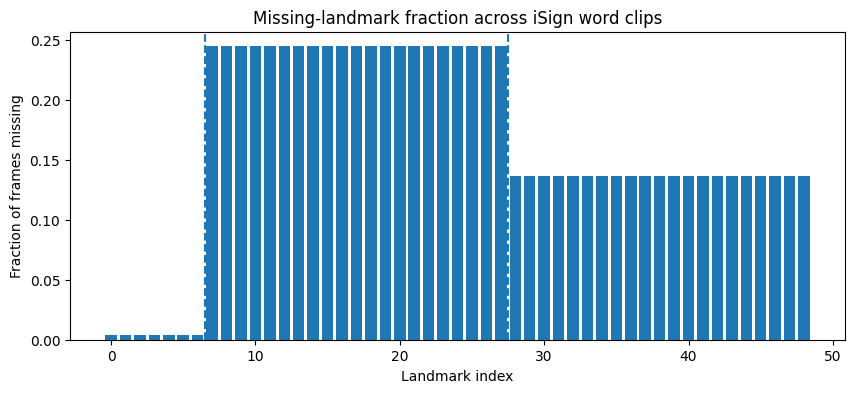

In [19]:
BODY_NAMES = ["nose", "left_shoulder", "right_shoulder",
              "left_elbow", "right_elbow", "left_wrist", "right_wrist"]

def landmark_present(a):
    return np.abs(np.asarray(a)).sum(axis=-1) > 0

all_word_frames = []
per_clip_visibility = []

for uid, a in word_pose.items():
    present = landmark_present(a)
    all_word_frames.append(present)
    left = present[:, 7:28].any(axis=1)
    right = present[:, 28:49].any(axis=1)
    per_clip_visibility.append({
        "uid": uid,
        "left_visible": left.mean(),
        "right_visible": right.mean(),
        "both_visible": (left & right).mean(),
        "neither_visible": (~left & ~right).mean(),
        "frames": len(a)
    })

present_all = np.concatenate(all_word_frames, axis=0)
visibility_df = pd.DataFrame(per_clip_visibility)

print("Total word-pose frames:", len(present_all))
print("\nMean per-recording hand visibility:")
display(
    visibility_df[["left_visible", "right_visible",
                   "both_visible", "neither_visible"]]
    .mean().to_frame("mean_fraction")
)

missing_rate = 1 - present_all.mean(axis=0)
missing_df = pd.DataFrame({
    "landmark_index": np.arange(49),
    "missing_fraction": missing_rate
})
display(missing_df)

left_consistency = np.mean([
    np.all(p[:, 7:28] == p[:, 7:8], axis=1).mean()
    for p in all_word_frames
])
right_consistency = np.mean([
    np.all(p[:, 28:49] == p[:, 28:29], axis=1).mean()
    for p in all_word_frames
])

print("Left-hand group consistency:", round(float(left_consistency), 4))
print("Right-hand group consistency:", round(float(right_consistency), 4))

plt.figure(figsize=(10, 4))
plt.bar(np.arange(49), missing_rate)
plt.axvline(6.5, linestyle="--")
plt.axvline(27.5, linestyle="--")
plt.title("Missing-landmark fraction across iSign word clips")
plt.xlabel("Landmark index")
plt.ylabel("Fraction of frames missing")
plt.show()

/tmp/ipykernel_557/1211328128.py:16: RuntimeWarning: All-NaN slice encountered
  e = np.nanmedian(speed, axis=1)


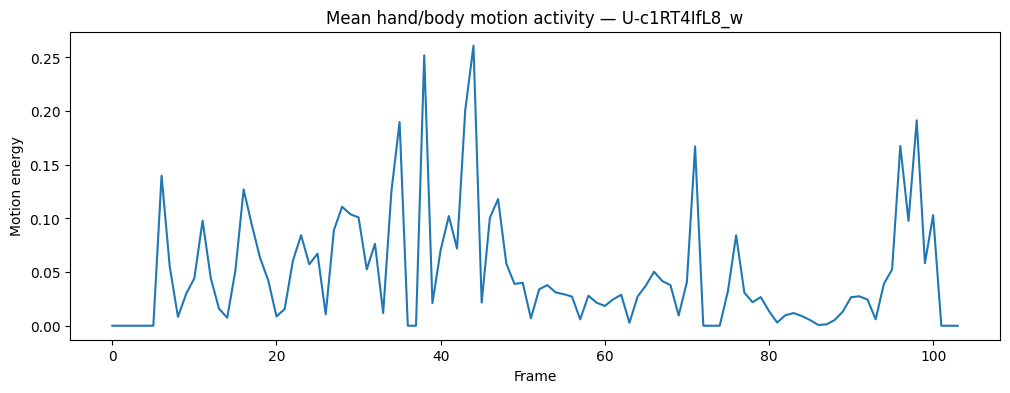

Sample clip: U-c1RT4IfL8_w
Pose shape: (104, 49, 2)
Frames: 104


In [20]:
# Example pose and motion plot. The `ashamed` recording is used when available.
sample_uid = next(
    (u for u in word_pose if word_meta.set_index("uid").loc[u, "label"] == "ashamed"),
    next(iter(word_pose))
)
sample_pose = word_pose[sample_uid]

def motion_energy(a):
    a = np.asarray(a, dtype=np.float32)
    xy = a[:, 7:49]
    vis = landmark_present(xy)
    delta = np.diff(xy, axis=0)
    valid = vis[1:] & vis[:-1]
    speed = np.linalg.norm(delta, axis=-1)
    speed[~valid] = np.nan
    e = np.nanmedian(speed, axis=1)
    e = np.nan_to_num(e, nan=0.0)
    return np.r_[0.0, e]

energy = motion_energy(sample_pose)
plt.figure(figsize=(12, 4))
plt.plot(energy)
plt.title(f"Mean hand/body motion activity — {sample_uid}")
plt.xlabel("Frame")
plt.ylabel("Motion energy")
plt.show()

print("Sample clip:", sample_uid)
print("Pose shape:", sample_pose.shape)
print("Frames:", len(sample_pose))

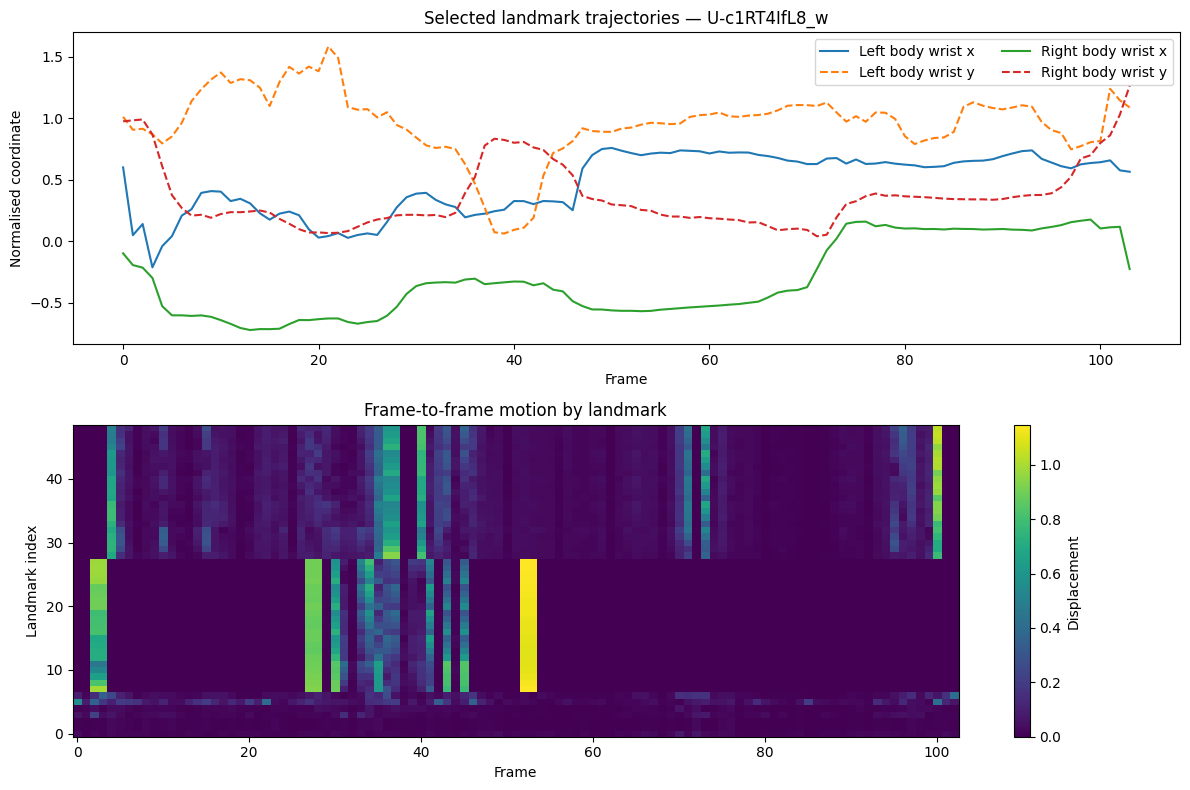

In [21]:
# Landmark trajectories and per-landmark motion heatmap for the sample word clip.
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for landmark, name in [(5, "Left body wrist"), (6, "Right body wrist")]:
    axes[0].plot(sample_pose[:, landmark, 0], label=f"{name} x")
    axes[0].plot(sample_pose[:, landmark, 1], linestyle="--", label=f"{name} y")
axes[0].set_title(f"Selected landmark trajectories — {sample_uid}")
axes[0].set_xlabel("Frame")
axes[0].set_ylabel("Normalised coordinate")
axes[0].legend(ncol=2)

landmark_motion = np.linalg.norm(np.diff(sample_pose, axis=0), axis=-1)
image = axes[1].imshow(landmark_motion.T, aspect="auto", origin="lower")
axes[1].set_title("Frame-to-frame motion by landmark")
axes[1].set_xlabel("Frame")
axes[1].set_ylabel("Landmark index")
fig.colorbar(image, ax=axes[1], label="Displacement")
plt.tight_layout()
plt.show()


**Interpretation caution:** peaks and valleys in motion energy indicate changes in movement activity. They are not linguistic word boundaries. The iSign metadata inspected here has no frame-level alignment labels, so segmentation precision, recall and F1 must not be reported.

## 4. Pose features and augmentations

We resample each sequence to a fixed number of frames. The frame descriptor contains:

- 8 trajectory coordinates from selected wrist/hand-root landmarks
- 8 corresponding velocity values
- 84 wrist-relative handshape coordinates
- 2 hand-visibility indicators

Total: **102 features per frame**.

The visibility indicators are included because absent hands are represented by zero coordinates in the pose cache. We do not interpolate missing hands.

In [22]:
def active_clip(a, pad=2):
    a = np.asarray(a, dtype=np.float32)
    if len(a) == 0:
        return a
    p = landmark_present(a[:, 7:49]).any(axis=1)
    if p.sum() < 2:
        return a
    idx = np.where(p)[0]
    return a[max(0, idx[0]-pad):min(len(a), idx[-1]+pad+1)]

def resample_pose(a, T=N_FRAMES):
    a = active_clip(a)
    if len(a) == 0:
        return np.zeros((T, 49, 2), np.float32)
    idx = np.linspace(0, len(a)-1, T).round().astype(int)
    return a[idx].astype(np.float32)

def handshape_features(x):
    outputs = []
    for sl in (slice(7, 28), slice(28, 49)):
        hand = x[:, sl, :]
        present = landmark_present(hand)
        wrist_ok = present[:, 0]
        mcp_ok = present[:, 9]
        scale = np.linalg.norm(hand[:, 9] - hand[:, 0], axis=-1)
        valid = wrist_ok & mcp_ok & np.isfinite(scale) & (scale > 1e-3)

        rel = np.zeros_like(hand)
        rel[valid] = (
            hand[valid] - hand[valid, :1]
        ) / scale[valid, None, None]
        rel[~present] = 0
        rel[~valid] = 0
        outputs.append(rel.reshape(len(x), 42))
    return np.concatenate(outputs, axis=1)

def sequence_features(a, T=N_FRAMES):
    x = resample_pose(a, T)
    trajectory = x[:, [5, 6, 7, 28], :].reshape(T, 8)
    velocity = np.vstack([
        np.zeros((1, 8), np.float32),
        np.diff(trajectory, axis=0)
    ])
    handshape = handshape_features(x)

    left_visible = landmark_present(x[:, 7:28]).any(axis=1).astype(np.float32)
    right_visible = landmark_present(x[:, 28:49]).any(axis=1).astype(np.float32)
    visibility = np.stack([left_visible, right_visible], axis=1)

    features = np.concatenate(
        [trajectory, velocity, handshape, visibility], axis=1
    ).astype(np.float32)

    assert features.shape == (T, FEATURE_DIM)
    return features

test_features = sequence_features(sample_pose)
print("Feature shape:", test_features.shape)
print("Feature dimension:", test_features.shape[-1])
assert test_features.shape == (N_FRAMES, FEATURE_DIM)

Feature shape: (32, 102)
Feature dimension: 102


In [23]:
def augment_pose(a, rng):
    a = active_clip(a).copy()
    if len(a) < 4:
        return a

    keep = max(4, int(len(a) * rng.uniform(0.80, 1.0)))
    start = int(rng.integers(0, max(1, len(a)-keep+1)))
    a = a[start:start+keep]

    new_len = int(np.clip(len(a) * rng.uniform(0.85, 1.20), 8, 220))
    a = a[np.linspace(0, len(a)-1, new_len).round().astype(int)].copy()

    present = landmark_present(a)
    theta = rng.normal(0, 0.06)
    scale = rng.uniform(0.92, 1.08)
    rotation = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ], dtype=np.float32) * scale

    a = a @ rotation.T
    a += rng.normal(0, 0.003, size=a.shape).astype(np.float32)
    a[~present] = 0

    # Occasionally drop one complete hand to improve robustness to occlusion.
    if rng.random() < 0.08:
        hand_slice = slice(7, 28) if rng.random() < 0.5 else slice(28, 49)
        a[:, hand_slice] = 0

    return a.astype(np.float32)

def batch_tensor(arrays):
    return torch.tensor(
        np.stack(arrays), dtype=torch.float32, device=DEVICE
    )

def nt_xent(z1, z2, temperature=TEMPERATURE, group_ids=None):
    z = torch.cat([z1, z2], dim=0)
    logits = (z @ z.T) / temperature
    logits.fill_diagonal_(-1e9)
    n = len(z1)
    targets = torch.cat([
        torch.arange(n, 2*n),
        torch.arange(0, n)
    ]).to(z.device)

    # Exclude other clips from the same source video as negatives.
    if group_ids is not None:
        all_groups = list(group_ids) + list(group_ids)
        same_group = np.equal.outer(all_groups, all_groups)
        np.fill_diagonal(same_group, False)
        same_group[np.arange(2*n), targets.detach().cpu().numpy()] = False
        logits[torch.as_tensor(same_group, device=z.device)] = -1e9

    return F.cross_entropy(logits, targets)

## 5. iSign-only self-supervised Transformer pretraining

The model sees two augmented views of the same iSign clip as a positive pair. Other clips in the batch provide negative examples. No iSign word labels or sentence text are used in the training loss.

**This is instance-level self-supervised learning.** It encourages invariance to the chosen augmentations; it does not directly learn that different recordings of the same sign should have identical embeddings.

In [24]:
class PoseTransformer(nn.Module):
    def __init__(self, d_in=FEATURE_DIM, d_model=128,
                 layers=2, heads=4, out_dim=128, dropout=0.2):
        super().__init__()
        self.input = nn.Sequential(
            nn.LayerNorm(d_in),
            nn.Linear(d_in, d_model)
        )
        self.position = nn.Parameter(
            torch.randn(1, N_FRAMES, d_model) * 0.02
        )
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=heads,
            dim_feedforward=2*d_model,
            dropout=dropout,
            batch_first=True,
            norm_first=True
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=layers
        )
        self.projection = nn.Linear(d_model, out_dim)

    def forward(self, x):
        h = self.input(x) + self.position
        h = self.encoder(h).mean(dim=1)
        return F.normalize(self.projection(h), dim=-1)

def train_contrastive(
    clips, seed=SEED, epochs=PRETRAIN_EPOCHS,
    batch_size=BATCH_SIZE, lr=LEARNING_RATE,
    verbose=True, clip_groups=None
):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    model = PoseTransformer().to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr, weight_decay=1e-2
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs
    )
    history = []

    for epoch in range(epochs):
        model.train()
        order = rng.permutation(len(clips))
        losses = []

        for start in range(0, len(order)-batch_size+1, batch_size):
            ids = order[start:start+batch_size]
            base = [clips[i] for i in ids]

            view1 = batch_tensor([
                sequence_features(augment_pose(a, rng))
                for a in base
            ])
            view2 = batch_tensor([
                sequence_features(augment_pose(a, rng))
                for a in base
            ])

            batch_groups = [clip_groups[i] for i in ids] if clip_groups is not None else None
            loss = nt_xent(model(view1), model(view2), group_ids=batch_groups)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        scheduler.step()
        epoch_loss = float(np.mean(losses)) if losses else np.nan
        history.append(epoch_loss)

        if verbose and ((epoch+1) % 5 == 0 or epoch == 0):
            print(f"Epoch {epoch+1:3d}/{epochs} | loss {epoch_loss:.4f}")

    return model, history

print("iSign pretraining clips:", len(isign_train_clips))
print("Device:", DEVICE)

iSign pretraining clips: 2052
Device: cuda


/tmp/ipykernel_557/2763088477.py:20: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Epoch   1/60 | loss 3.1872
Epoch   5/60 | loss 0.9589
Epoch  10/60 | loss 0.7038
Epoch  15/60 | loss 0.6009
Epoch  20/60 | loss 0.5351
Epoch  25/60 | loss 0.5178
Epoch  30/60 | loss 0.4485
Epoch  35/60 | loss 0.4575
Epoch  40/60 | loss 0.4237
Epoch  45/60 | loss 0.4104
Epoch  50/60 | loss 0.3918
Epoch  55/60 | loss 0.3963
Epoch  60/60 | loss 0.3865


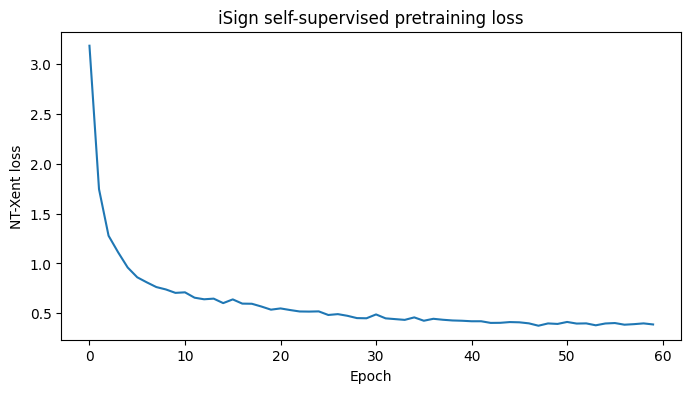

Saved iSign-pretrained encoder.


In [25]:
# Set PRETRAIN_EPOCHS in Section 0 to a smaller value for a smoke test.
def isign_base_id(uid):
    return re.sub(r"_(?:w|d|e\d+)$", "", str(uid))

isign_train_groups = [isign_base_id(uid) for uid in isign_train_ids]

isign_model, isign_loss_history = train_contrastive(
    isign_train_clips,
    seed=SEED,
    epochs=PRETRAIN_EPOCHS,
    batch_size=BATCH_SIZE,
    clip_groups=isign_train_groups
)

plt.figure(figsize=(8, 4))
plt.plot(isign_loss_history)
plt.title("iSign self-supervised pretraining loss")
plt.xlabel("Epoch")
plt.ylabel("NT-Xent loss")
plt.show()

torch.save(
    {
        "state_dict": isign_model.state_dict(),
        "input_dim": FEATURE_DIM,
        "sequence_length": N_FRAMES,
        "pretraining_dataset": "iSign",
        "pretraining_clips": len(isign_train_clips),
        "seed": SEED,
        "epochs": PRETRAIN_EPOCHS
    },
    OUTPUT_DIR / "isign_pretrained_transformer.pt"
)
print("Saved iSign-pretrained encoder.")

In [26]:
print("Pretraining clips:", len(isign_train_clips))
print("Word clips:", len(isign_word_clips))
print("Sentence clips:", len(isign_sentence_clips))

Pretraining clips: 2052
Word clips: 561
Sentence clips: 1492


In [28]:
from pathlib import Path

meta_path = Path('/content/drive/MyDrive/isl_project/isign/word-presence-dataset_v1.1.csv')

print("Metadata file exists:", meta_path.exists())

Metadata file exists: True


In [29]:
print("Metadata path:", meta_path)
print("Metadata file exists:", meta_path.exists())

print("\nSentence IDs matched:", len(sentence_ids & set(isign_clips)))
print("Word IDs matched:", len(word_ids & set(isign_clips)))

short_clips = {
    uid: len(arr)
    for uid, arr in isign_clips.items()
    if len(arr) < 12
}

print("\nClips shorter than 12 frames:", len(short_clips))
print("Short clip examples:", list(short_clips.items())[:10])

print("\nExpected sentence clips:", sum(
    len(isign_clips[uid]) >= 12
    for uid in sentence_ids & set(isign_clips)
))

Metadata path: /content/drive/MyDrive/isl_project/isign/word-presence-dataset_v1.1.csv
Metadata file exists: True

Sentence IDs matched: 1492
Word IDs matched: 561

Clips shorter than 12 frames: 1
Short clip examples: [('iG66ukXl8o0_e4', 10)]

Expected sentence clips: 1491


In [31]:
sentence_clips = [
    isign_clips[uid]
    for uid in sentence_ids
    if uid in isign_clips
]

sentence_clips = [
    arr for arr in sentence_clips
    if len(arr) >= 12
]

all_clips = [
    arr for arr in isign_clips.values()
    if len(arr) >= 12
]

print("Sentence-only clips:", len(sentence_clips))
print("All eligible clips:", len(all_clips))
print("Previously used for pretraining:", len(isign_train_clips))

Sentence-only clips: 1491
All eligible clips: 2052
Previously used for pretraining: 2052


## 6. Load CISLR metadata and pose cache

CISLR is used only for the recognition evaluation. The official prototype clips are reference examples; the official test clips are queries. Existing pose-cache chunks are reused. If some clips are missing, the optional extraction cell below can fill the gaps when the videos are available.

In [32]:
def ensure_cislr_metadata():
    if not (CIS_ROOT / "prototype.csv").exists() or not (CIS_ROOT / "test.csv").exists():
        snapshot_download(
            repo_id="Exploration-Lab/CISLR",
            repo_type="dataset",
            local_dir=str(CIS_ROOT),
            allow_patterns=["*.csv"]
        )

ensure_cislr_metadata()

proto_all = pd.read_csv(CIS_ROOT / "prototype.csv")
test_all = pd.read_csv(CIS_ROOT / "test.csv")

for df in [proto_all, test_all]:
    df["uid"] = df["uid"].astype(str)
    df["gloss"] = df["gloss"].astype(str).str.lower().str.strip()

print("Prototype metadata:", proto_all.shape)
print("Test metadata:", test_all.shape)
print("Prototype columns:", proto_all.columns.tolist())
print("Test columns:", test_all.columns.tolist())

def load_npz_cache(cache_dir):
    result = {}
    for p in sorted(Path(cache_dir).glob("chunk_*.npz")):
        with np.load(p) as z:
            for uid in z.files:
                result[uid] = z[uid].astype(np.float32)
    return result

cislr_clips = load_npz_cache(CIS_CACHE)
print("Cached CISLR pose clips:", len(cislr_clips))

print("Prototype rows with cached poses:",
      proto_all.uid.isin(cislr_clips).sum(), "/", len(proto_all))
print("Test rows with cached poses:",
      test_all.uid.isin(cislr_clips).sum(), "/", len(test_all))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Prototype metadata: (4765, 4)
Test metadata: (2285, 4)
Prototype columns: ['uid', 'gloss', 'duration', 'category']
Test columns: ['uid', 'gloss', 'duration', 'category']
Cached CISLR pose clips: 2674
Prototype rows with cached poses: 1000 / 4765
Test rows with cached poses: 1674 / 2285


In [33]:
print("\nMissing prototype poses:",
      (~proto_all.uid.isin(cislr_clips)).sum())

print("Missing test poses:",
      (~test_all.uid.isin(cislr_clips)).sum())

shapes = {}

for uid, arr in cislr_clips.items():
    shapes[arr.shape] = shapes.get(arr.shape, 0) + 1

print("\nPose array shapes:")
for shape, count in shapes.items():
    print(shape, ":", count)


Missing prototype poses: 3765
Missing test poses: 611

Pose array shapes:
(29, 49, 2) : 7
(38, 49, 2) : 392
(53, 49, 2) : 145
(40, 49, 2) : 45
(44, 49, 2) : 160
(46, 49, 2) : 51
(66, 49, 2) : 18
(51, 49, 2) : 54
(56, 49, 2) : 26
(33, 49, 2) : 14
(45, 49, 2) : 266
(34, 49, 2) : 29
(39, 49, 2) : 56
(50, 49, 2) : 78
(48, 49, 2) : 56
(55, 49, 2) : 31
(59, 49, 2) : 20
(37, 49, 2) : 23
(42, 49, 2) : 43
(82, 49, 2) : 2
(32, 49, 2) : 172
(68, 49, 2) : 59
(49, 49, 2) : 55
(60, 49, 2) : 141
(35, 49, 2) : 30
(25, 49, 2) : 15
(75, 49, 2) : 37
(54, 49, 2) : 43
(63, 49, 2) : 22
(83, 49, 2) : 10
(36, 49, 2) : 20
(65, 49, 2) : 15
(52, 49, 2) : 37
(57, 49, 2) : 32
(58, 49, 2) : 24
(87, 49, 2) : 7
(43, 49, 2) : 49
(74, 49, 2) : 8
(156, 49, 2) : 3
(70, 49, 2) : 9
(84, 49, 2) : 8
(41, 49, 2) : 43
(97, 49, 2) : 1
(72, 49, 2) : 11
(47, 49, 2) : 38
(142, 49, 2) : 5
(30, 49, 2) : 18
(76, 49, 2) : 9
(61, 49, 2) : 21
(137, 49, 2) : 1
(62, 49, 2) : 15
(100, 49, 2) : 2
(127, 49, 2) : 3
(89, 49, 2) : 1
(16, 49, 2

In [34]:
print("PROTOTYPE")
print("Rows:", len(proto_all))
print("Unique UIDs:", proto_all.uid.nunique())
print("Unique glosses:", proto_all.gloss.nunique())

print("\nTEST")
print("Rows:", len(test_all))
print("Unique UIDs:", test_all.uid.nunique())
print("Unique glosses:", test_all.gloss.nunique())

print("\nUID overlap:",
      len(set(proto_all.uid) & set(test_all.uid)))

print("\nCached prototype glosses:",
      proto_all[proto_all.uid.isin(cislr_clips)].gloss.nunique())

print("Cached test glosses:",
      test_all[test_all.uid.isin(cislr_clips)].gloss.nunique())

PROTOTYPE
Rows: 4765
Unique UIDs: 4765
Unique glosses: 4765

TEST
Rows: 2285
Unique UIDs: 2285
Unique glosses: 1363

UID overlap: 0

Cached prototype glosses: 1000
Cached test glosses: 1000


In [35]:
proto_cached = proto_all[proto_all.uid.isin(cislr_clips)].copy()
test_cached = test_all[test_all.uid.isin(cislr_clips)].copy()

proto_glosses = set(proto_cached.gloss)
test_glosses = set(test_cached.gloss)

print("PROTOTYPE LABEL EXAMPLES:")
print(proto_cached[['uid', 'gloss', 'category']].head(10).to_string(index=False))

print("\nTEST LABEL EXAMPLES:")
print(test_cached[['uid', 'gloss', 'category']].head(10).to_string(index=False))

print("\nVOCABULARY COMPARISON")
print("Prototype unique glosses:", len(proto_glosses))
print("Test unique glosses:", len(test_glosses))
print("Shared glosses:", len(proto_glosses & test_glosses))
print("Prototype-only glosses:", len(proto_glosses - test_glosses))
print("Test-only glosses:", len(test_glosses - proto_glosses))

print("\nPROTOTYPE DUPLICATE GLOSSES:")
print(proto_cached.gloss.value_counts().head(10))

print("\nTEST DUPLICATE GLOSSES:")
print(test_cached.gloss.value_counts().head(10))

PROTOTYPE LABEL EXAMPLES:
          uid          gloss        category
-0XujLX2_9I_2    application          action
  -4MbWP5T-cU      thank you         gesture
-5p4hn8J87A_2           hour            time
-8CjLUfRlbw_1            pig flora and fauna
  -C18cQCkCcw         pencil    utility item
-DDBcacIfeA_1      cosmetics       substance
-Em79Yvwac4_1          think          action
  -It9bwqowig        twitter        internet
  -JcpfOHc0nE blood pressure         medical
  -MS1EdYqs48        gujarat       geography

TEST LABEL EXAMPLES:
          uid           gloss     category
-NIz596Y27Q_1       severally     quantity
08E4Dr0zyKk_2      difference   comparator
0i1qCUd3BdM_1        increase   comparator
  0p_iET-2TRw          pencil utility item
0q7mwfrGneM_1          monday         time
10KuxOH6cYM_1        interest     behavior
1DMSk1W0LSY_1        amritsar    geography
  1KCDw7XLgU0 mahavir jayanti        event
  1XFe7SCIQKw       anonymous     abstract
2DAexoF0SsA_1           thi

In [36]:
import re

def get_source_id(uid):
    return re.sub(r'_\d+$', '', str(uid))

proto_sources = set(
    proto_cached.uid.map(get_source_id)
)

test_sources = set(
    test_cached.uid.map(get_source_id)
)

overlap = proto_sources & test_sources

print("Prototype source IDs:", len(proto_sources))
print("Test source IDs:", len(test_sources))
print("Overlapping source IDs:", len(overlap))
print("Examples:", list(overlap)[:10])

Prototype source IDs: 1000
Test source IDs: 1673
Overlapping source IDs: 2
Examples: ['YzFnEXBbgqk', '-NIz596Y27Q']


In [37]:
for source in sorted(overlap):
    print("\nSOURCE:", source)

    print("\nPrototype recordings:")
    print(
        proto_cached[
            proto_cached.uid.map(get_source_id) == source
        ][['uid', 'gloss', 'category']].to_string(index=False)
    )

    print("\nTest recordings:")
    print(
        test_cached[
            test_cached.uid.map(get_source_id) == source
        ][['uid', 'gloss', 'category']].to_string(index=False)
    )


SOURCE: -NIz596Y27Q

Prototype recordings:
        uid     gloss category
-NIz596Y27Q severally quantity

Test recordings:
          uid     gloss category
-NIz596Y27Q_1 severally quantity

SOURCE: YzFnEXBbgqk

Prototype recordings:
        uid           gloss  category
YzFnEXBbgqk railway station transport

Test recordings:
          uid           gloss  category
YzFnEXBbgqk_1 railway station transport


In [38]:
overlapping_sources = {
    '-NIz596Y27Q',
    'YzFnEXBbgqk'
}

test_clean = test_cached[
    ~test_cached.uid.map(get_source_id).isin(overlapping_sources)
].copy()

print("Original cached test recordings:", len(test_cached))
print("Filtered test recordings:", len(test_clean))
print("Removed recordings:", len(test_cached) - len(test_clean))

remaining_sources = set(
    test_clean.uid.map(get_source_id)
)

print("Remaining source overlap:",
      len(proto_sources & remaining_sources))

print("Remaining test vocabulary:",
      test_clean.gloss.nunique())

print("Missing prototype classes:",
      len(set(proto_cached.gloss) - set(test_clean.gloss)))

Original cached test recordings: 1674
Filtered test recordings: 1672
Removed recordings: 2
Remaining source overlap: 0
Remaining test vocabulary: 998
Missing prototype classes: 2


In [39]:
eval_glosses = set(test_clean.gloss)

proto_clean = proto_cached[
    proto_cached.gloss.isin(eval_glosses)
].copy()

test_clean = test_clean[
    test_clean.gloss.isin(set(proto_clean.gloss))
].copy()

print("Prototype recordings:", len(proto_clean))
print("Test recordings:", len(test_clean))
print("Prototype classes:", proto_clean.gloss.nunique())
print("Test classes:", test_clean.gloss.nunique())

print("Source overlap:", len(
    set(proto_clean.uid.map(get_source_id)) &
    set(test_clean.uid.map(get_source_id))
))

print("Missing test classes:", len(
    set(proto_clean.gloss) - set(test_clean.gloss)
))

Prototype recordings: 998
Test recordings: 1672
Prototype classes: 998
Test classes: 998
Source overlap: 0
Missing test classes: 0


### 6.1 Optional: extract missing CISLR poses

Run this only if the cache does not contain the required clips and the CISLR videos are available. It uses the same 49-landmark layout and shoulder-based normalisation as the existing cache. This can take substantial time.

In [ ]:
RUN_CISLR_EXTRACTION = False

if RUN_CISLR_EXTRACTION:
    import cv2
    import mediapipe as mp
    from mediapipe.tasks import python as mp_python
    from mediapipe.tasks.python import vision

    VIDEO_DIR = CIS_ROOT / "videos"
    VIDEO_DIR.mkdir(parents=True, exist_ok=True)

    videos = list(VIDEO_DIR.rglob("*.mp4"))
    if not videos:
        snapshot_download(
            repo_id="Exploration-Lab/CISLR",
            repo_type="dataset",
            local_dir=str(CIS_ROOT),
            allow_patterns=["CISLR_v1.5-a_videos/*"]
        )
        zip_files = list(CIS_ROOT.rglob("CISLR_v1.5-a_videos.zip"))
        if zip_files:
            with zipfile.ZipFile(zip_files[0]) as zf:
                zf.extractall(VIDEO_DIR)
        videos = list(VIDEO_DIR.rglob("*.mp4"))

    video_paths = {p.stem: str(p) for p in videos}
    wanted = set(proto_all.uid) | set(test_all.uid)
    todo = sorted(
        uid for uid in wanted
        if uid not in cislr_clips and uid in video_paths
    )
    print("Missing clips with video files:", len(todo))

    model_base = "https://storage.googleapis.com/mediapipe-models/"
    model_urls = {
        "pose.task": model_base + "pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task",
        "hand.task": model_base + "hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
    }
    for filename, url in model_urls.items():
        target = Path("/content") / filename
        if not target.exists():
            urllib.request.urlretrieve(url, target)

    body_indices = [0, 11, 12, 13, 14, 15, 16]

    pose_options = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path="/content/pose.task"),
        running_mode=vision.RunningMode.VIDEO
    )
    hand_options = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path="/content/hand.task"),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )
    pose_model = vision.PoseLandmarker.create_from_options(pose_options)
    hand_model = vision.HandLandmarker.create_from_options(hand_options)

    def extract_video_pose(path, stride=2):
        cap = cv2.VideoCapture(path)
        fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
        frames, frame_i = [], 0
        while True:
            ok, bgr = cap.read()
            if not ok:
                break
            current = frame_i
            frame_i += 1
            if current % stride:
                continue
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            timestamp = int(current * 1000 / fps)
            pr = pose_model.detect_for_video(image, timestamp)
            hr = hand_model.detect_for_video(image, timestamp)

            f = np.zeros((49, 2), np.float32)
            if pr.pose_landmarks:
                body = pr.pose_landmarks[0]
                f[:7] = [[body[j].x, body[j].y] for j in body_indices]
                lw = np.array([body[15].x, body[15].y])
                rw = np.array([body[16].x, body[16].y])
                for hand in hr.hand_landmarks:
                    wrist = np.array([hand[0].x, hand[0].y])
                    sl = slice(7, 28) if np.linalg.norm(wrist-lw) <= np.linalg.norm(wrist-rw) else slice(28, 49)
                    f[sl] = [[p.x, p.y] for p in hand]
            frames.append(f)
        cap.release()
        return np.stack(frames) if frames else np.zeros((0,49,2),np.float32)

    def normalize_pose_xy(x):
        x = x.astype(np.float32).copy()
        present = landmark_present(x)
        shoulders_ok = present[:,1] & present[:,2]
        if not shoulders_ok.any():
            return np.zeros_like(x)
        center = (x[:,1] + x[:,2]) / 2
        widths = np.linalg.norm(x[:,1] - x[:,2], axis=-1)
        valid_widths = widths[shoulders_ok & (widths > 1e-5)]
        scale = np.median(valid_widths) if len(valid_widths) else 1.0
        x = (x - center[:,None]) / max(float(scale), 1e-5)
        x[~present] = 0
        x[~shoulders_ok] = 0
        return x.astype(np.float32)

    batch = {}
    for i, uid in enumerate(todo, 1):
        try:
            raw = extract_video_pose(video_paths[uid])
            if len(raw) >= 2:
                batch[uid] = normalize_pose_xy(raw)
        except Exception as exc:
            print("Skipped", uid, type(exc).__name__, str(exc)[:100])

        if len(batch) >= 30 or i == len(todo):
            if batch:
                existing = sorted(CIS_CACHE.glob("chunk_*.npz"))
                nums = [
                    int(re.search(r"chunk_(\d+)", p.name).group(1))
                    for p in existing
                ]
                next_id = max(nums, default=-1) + 1
                np.savez_compressed(CIS_CACHE / f"chunk_{next_id:04d}.npz", **batch)
                cislr_clips.update(batch)
                batch = {}
            print(f"Processed {i}/{len(todo)}")

    pose_model.close()
    hand_model.close()
else:
    print("CISLR extraction disabled; using existing pose cache.")

## 7. Source-independent CISLR evaluation split

The split is made by source ID, not by individual clip. A suffix such as `_12` is removed to identify clips originating from the same base video. Prototype sources are excluded from the query pool. A gloss is retained only if it has one available prototype and at least two independent query sources.

A group split is selected using metadata only, choosing the split that retains the largest number of glosses in both development and held-back partitions. Model performance is not used to choose the split.

In [41]:
def source_id(uid):
    return re.sub(r"_\d+$", "", str(uid))

P0 = proto_all[proto_all.uid.isin(cislr_clips)].copy()
Q0 = test_all[test_all.uid.isin(cislr_clips)].copy()

P0["source_id"] = P0["uid"].map(source_id)
Q0["source_id"] = Q0["uid"].map(source_id)

# Keep glosses with exactly one official prototype.
prototype_counts = P0.groupby("gloss").uid.nunique()
one_prototype_glosses = set(prototype_counts[prototype_counts == 1].index)
P0 = P0[P0.gloss.isin(one_prototype_glosses)].copy()

prototype_sources = set(P0.source_id)
Q0 = Q0[~Q0.source_id.isin(prototype_sources)].copy()

query_source_counts = Q0.groupby("gloss").source_id.nunique()
eligible_glosses = sorted(
    set(P0.gloss) &
    set(query_source_counts[query_source_counts >= 2].index)
)

P = P0[P0.gloss.isin(eligible_glosses)].copy()
Q = Q0[Q0.gloss.isin(eligible_glosses)].copy()

print("Eligible vocabulary:", len(eligible_glosses))
print("Prototype clips:", len(P))
print("Query clips:", len(Q))
print("Independent query sources:", Q.source_id.nunique())

assert P.groupby("gloss").size().eq(1).all()
assert set(P.gloss) == set(eligible_glosses)
assert set(P.source_id).isdisjoint(set(Q.source_id))

# Search deterministic group splits and keep the split with the most
# glosses represented in both partitions.
best = None
groups = Q["source_id"].to_numpy()
y = Q["gloss"].to_numpy()

for random_state in range(100, 150):
    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.70, random_state=random_state
    )
    dev_i, held_i = next(splitter.split(Q, y, groups))
    dev_glosses = set(Q.iloc[dev_i].gloss)
    held_glosses = set(Q.iloc[held_i].gloss)
    common = dev_glosses & held_glosses
    score = len(common)
    if best is None or score > best[0]:
        best = (score, random_state, dev_i, held_i, common)

_, split_seed, dev_i, held_i, common_glosses = best

# Capture source IDs while Q still has the original row order used by GroupShuffleSplit.
dev_sources = set(Q.iloc[dev_i].source_id)
held_sources = set(Q.iloc[held_i].source_id)

P = P[P.gloss.isin(common_glosses)].sort_values("gloss").reset_index(drop=True)
Q = Q[Q.gloss.isin(common_glosses)].reset_index(drop=True)

# Reconstruct indices in the filtered query table using source-ID groups.
dev_idx = np.where(Q.source_id.isin(dev_sources))[0]
held_idx = np.where(Q.source_id.isin(held_sources))[0]

print("Selected split seed:", split_seed)
print("Final vocabulary:", P.gloss.nunique())
print("Prototype clips:", len(P))
print("Development queries:", len(dev_idx))
print("Held-back queries:", len(held_idx))
print("Prototype/query source overlap:", len(set(P.source_id) & set(Q.source_id)))
print("Development/held-back source overlap:", len(dev_sources & held_sources))

assert set(P.gloss) == set(Q.iloc[dev_idx].gloss) == set(Q.iloc[held_idx].gloss)
assert set(P.source_id).isdisjoint(set(Q.source_id))
assert dev_sources.isdisjoint(held_sources)
print("\nSplit distribution:")
print("Development glosses:", Q.iloc[dev_idx].gloss.nunique())
print("Held-back glosses:", Q.iloc[held_idx].gloss.nunique())
print("Development source groups:", len(dev_sources))
print("Held-back source groups:", len(held_sources))

print("\nQueries per gloss:")
print(Q.iloc[dev_idx].groupby("gloss").size().describe())
print(Q.iloc[held_idx].groupby("gloss").size().describe())


Eligible vocabulary: 401
Prototype clips: 401
Query clips: 1075
Independent query sources: 1074
Selected split seed: 114
Final vocabulary: 229
Prototype clips: 229
Development queries: 285
Held-back queries: 376
Prototype/query source overlap: 0
Development/held-back source overlap: 0

Split distribution:
Development glosses: 229
Held-back glosses: 229
Development source groups: 322
Held-back source groups: 752

Queries per gloss:
count    229.000000
mean       1.244541
std        0.563143
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        6.000000
dtype: float64
count    229.000000
mean       1.641921
std        1.081417
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        7.000000
dtype: float64


## 8. Recognition features and handcrafted baseline

The same prototype set and query set are used for every model. The handcrafted baseline pools the 102-dimensional temporal descriptor and ranks prototypes by centred cosine similarity.

In [42]:
P_arr = [cislr_clips[u] for u in P.uid]
Q_arr = [cislr_clips[u] for u in Q.uid]
prototype_labels = P.gloss.to_numpy()
query_labels = Q.gloss.to_numpy()

X_proto = np.stack([
    sequence_features(a).mean(axis=0) for a in P_arr
])
X_query = np.stack([
    sequence_features(a).mean(axis=0) for a in Q_arr
])

def l2_normalize(x):
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-8)

def centered_cosine(query, proto):
    mean = proto.mean(axis=0, keepdims=True)
    return l2_normalize(query - mean) @ l2_normalize(proto - mean).T

S_handcrafted = centered_cosine(X_query, X_proto)

def topk_metrics(similarity, indices, ks=(1, 5, 10)):
    order = np.argsort(-similarity[indices], axis=1)
    scores = {}
    for k in ks:
        hits = [
            query_labels[i] in set(prototype_labels[order[row, :min(k, len(prototype_labels))]])
            for row, i in enumerate(indices)
        ]
        scores[f"top{k}"] = float(np.mean(hits)) if hits else np.nan
    return scores

def macro_top1(similarity, indices):
    order = np.argsort(-similarity[indices], axis=1)[:, 0]
    per_class = {}
    for row, i in enumerate(indices):
        gloss = query_labels[i]
        per_class.setdefault(gloss, []).append(
            prototype_labels[order[row]] == gloss
        )
    return float(np.mean([np.mean(v) for v in per_class.values()]))

baseline_dev = topk_metrics(S_handcrafted, dev_idx)
baseline_held = topk_metrics(S_handcrafted, held_idx)

print("Handcrafted baseline — development:", baseline_dev)
print("Handcrafted baseline — held-back:", baseline_held)
print("Handcrafted macro Top-1 — held-back:", macro_top1(S_handcrafted, held_idx))
print("Uniform random Top-1 reference:", round(1 / len(prototype_labels), 5))

Handcrafted baseline — development: {'top1': 0.16842105263157894, 'top5': 0.24210526315789474, 'top10': 0.2771929824561403}
Handcrafted baseline — held-back: {'top1': 0.13297872340425532, 'top5': 0.21808510638297873, 'top10': 0.27393617021276595}
Handcrafted macro Top-1 — held-back: 0.14934497816593884
Uniform random Top-1 reference: 0.00437


### 8.1 Evaluate the iSign-pretrained encoder on CISLR

The iSign encoder is frozen. CISLR prototype clips are embedded and used as one-shot references. No CISLR query clip is used for training or model selection.

In [43]:
@torch.no_grad()
def encode_clips(model, clips, batch_size=128):
    model.eval()
    outputs = []
    for start in range(0, len(clips), batch_size):
        batch = batch_tensor([
            sequence_features(a) for a in clips[start:start+batch_size]
        ])
        outputs.append(model(batch).cpu().numpy())
    return np.concatenate(outputs, axis=0)

Z_proto_isign = encode_clips(isign_model, P_arr)
Z_query_isign = encode_clips(isign_model, Q_arr)
Z_proto_isign = l2_normalize(Z_proto_isign)
Z_query_isign = l2_normalize(Z_query_isign)

S_isign_pretrained = Z_query_isign @ Z_proto_isign.T
isign_dev = topk_metrics(S_isign_pretrained, dev_idx)
isign_held = topk_metrics(S_isign_pretrained, held_idx)

print("iSign-pretrained encoder — development:", isign_dev)
print("iSign-pretrained encoder — held-back:", isign_held)
print("iSign-pretrained macro Top-1 — held-back:",
      macro_top1(S_isign_pretrained, held_idx))

assert S_isign_pretrained.shape == (len(Q), len(P))

iSign-pretrained encoder — development: {'top1': 0.19649122807017544, 'top5': 0.3333333333333333, 'top10': 0.37543859649122807}
iSign-pretrained encoder — held-back: {'top1': 0.18882978723404256, 'top5': 0.30319148936170215, 'top10': 0.3537234042553192}
iSign-pretrained macro Top-1 — held-back: 0.2098981077147016


In [44]:
import pandas as pd
import json
from pathlib import Path

results = pd.DataFrame([
    {
        "Model": "Handcrafted",
        "Split": "Development",
        **baseline_dev
    },
    {
        "Model": "Handcrafted",
        "Split": "Held-back",
        **baseline_held,
        "macro_top1": macro_top1(S_handcrafted, held_idx)
    },
    {
        "Model": "iSign-pretrained Transformer",
        "Split": "Development",
        **isign_dev
    },
    {
        "Model": "iSign-pretrained Transformer",
        "Split": "Held-back",
        **isign_held,
        "macro_top1": macro_top1(S_isign_pretrained, held_idx)
    }
])

results_dir = ROOT / "results"
results_dir.mkdir(exist_ok=True)

results.to_csv(results_dir / "cislr_results.csv", index=False)

with open(results_dir / "cislr_results.json", "w") as f:
    json.dump(results.to_dict(orient="records"), f, indent=4)

print(results.to_string(index=False))
print("\nResults saved to:", results_dir)

                       Model       Split     top1     top5    top10  macro_top1
                 Handcrafted Development 0.168421 0.242105 0.277193         NaN
                 Handcrafted   Held-back 0.132979 0.218085 0.273936    0.149345
iSign-pretrained Transformer Development 0.196491 0.333333 0.375439         NaN
iSign-pretrained Transformer   Held-back 0.188830 0.303191 0.353723    0.209898

Results saved to: /content/drive/MyDrive/isl_project/results


## 9. CISLR-only contrastive control

This optional control trains the same architecture using only CISLR prototype clips, with the same instance-level contrastive objective. It helps distinguish the contribution of iSign pretraining from the effect of training a contrastive encoder on the target-domain prototype set.

It still does not use query/test clips for training.

In [45]:
RUN_CISLR_CONTROL = True

In [51]:
if RUN_CISLR_CONTROL:
    cislr_control_model, cislr_control_loss = train_contrastive(
        P_arr,
        seed=SEED,
        epochs=PRETRAIN_EPOCHS,
        batch_size=min(BATCH_SIZE, max(16, (len(P_arr)//16)*16))
    )

    Z_proto_control = encode_clips(cislr_control_model, P_arr)
    Z_query_control = encode_clips(cislr_control_model, Q_arr)
    S_cislr_control = Z_query_control @ Z_proto_control.T

    control_dev = topk_metrics(S_cislr_control, dev_idx)
    control_held = topk_metrics(S_cislr_control, held_idx)

    print("CISLR-only contrastive — development:", control_dev)
    print("CISLR-only contrastive — held-back:", control_held)
    print("CISLR control macro Top-1:",
          macro_top1(S_cislr_control, held_idx))

else:
    S_cislr_control = None
    print("CISLR-only control disabled.")

/tmp/ipykernel_557/2763088477.py:20: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Epoch   1/60 | loss 3.6803
Epoch   5/60 | loss 1.9598
Epoch  10/60 | loss 1.7923
Epoch  15/60 | loss 1.2846
Epoch  20/60 | loss 1.2394
Epoch  25/60 | loss 1.0027
Epoch  30/60 | loss 0.8329
Epoch  35/60 | loss 1.0271
Epoch  40/60 | loss 0.7662
Epoch  45/60 | loss 0.5944
Epoch  50/60 | loss 0.6652
Epoch  55/60 | loss 0.6174
Epoch  60/60 | loss 0.6900
CISLR-only contrastive — development: {'top1': 0.1824561403508772, 'top5': 0.2982456140350877, 'top10': 0.35789473684210527}
CISLR-only contrastive — held-back: {'top1': 0.15691489361702127, 'top5': 0.2845744680851064, 'top10': 0.34308510638297873}
CISLR control macro Top-1: 0.17627365356622998


In [52]:
results.loc[
    (results["Model"] == "Handcrafted") &
    (results["Split"] == "Held-back"),
    "macro_top1"
] = 0.1493449782

results.loc[
    (results["Model"] == "CISLR-only contrastive") &
    (results["Split"] == "Held-back"),
    "macro_top1"
] = 0.1762736536

results.loc[
    (results["Model"] == "iSign-pretrained Transformer") &
    (results["Split"] == "Held-back"),
    "macro_top1"
] = 0.2098981077

results.to_csv(results_dir / "cislr_results.csv", index=False)

with open(results_dir / "cislr_results.json", "w") as f:
    json.dump(results.to_dict(orient="records"), f, indent=4)

print(results.to_string(index=False))

                       Model       Split     top1     top5    top10  macro_top1
                 Handcrafted Development 0.168421 0.242105 0.277193         NaN
                 Handcrafted   Held-back 0.132979 0.218085 0.273936    0.149345
iSign-pretrained Transformer Development 0.196491 0.333333 0.375439         NaN
iSign-pretrained Transformer   Held-back 0.188830 0.303191 0.353723    0.209898


In [55]:

ISIGN_PRETRAIN_CLIPS = isign_train_clips
SEEDS = [42, 123, 2026]

all_results = []

def normalise_embeddings(Z):
    return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-8)

def evaluate_model(name, scores, seed):
    dev = topk_metrics(scores, dev_idx)
    held = topk_metrics(scores, held_idx)

    all_results.append({
        "Model": name,
        "Seed": seed,
        "Dev_Top1": dev["top1"],
        "Dev_Top5": dev["top5"],
        "Dev_Top10": dev["top10"],
        "Held_Top1": held["top1"],
        "Held_Top5": held["top5"],
        "Held_Top10": held["top10"],
        "Held_Macro_Top1": macro_top1(scores, held_idx)
    })

for seed in SEEDS:
    print(f"\nRunning seed {seed}")

    # 1. CISLR-only contrastive model
    control_model, control_loss = train_contrastive(
        P_arr,
        seed=seed,
        epochs=PRETRAIN_EPOCHS,
        batch_size=BATCH_SIZE
    )

    Zp = normalise_embeddings(encode_clips(control_model, P_arr))
    Zq = normalise_embeddings(encode_clips(control_model, Q_arr))
    control_scores = Zq @ Zp.T

    evaluate_model("CISLR-only contrastive", control_scores, seed)

    # 2. iSign-pretrained model
    isign_model, isign_loss = train_contrastive(
        ISIGN_PRETRAIN_CLIPS,
        seed=seed,
        epochs=PRETRAIN_EPOCHS,
        batch_size=BATCH_SIZE
    )

    Zp = normalise_embeddings(encode_clips(isign_model, P_arr))
    Zq = normalise_embeddings(encode_clips(isign_model, Q_arr))
    isign_scores = Zq @ Zp.T

    evaluate_model("iSign-pretrained", isign_scores, seed)

    print("Seed completed:", seed)

# Save individual seed results
multi_seed_results = pd.DataFrame(all_results)

# Calculate mean and standard deviation
summary_results = (
    multi_seed_results
    .groupby("Model")
    .agg(["mean", "std"])
    .round(4)
)

results_dir.mkdir(exist_ok=True)

multi_seed_results.to_csv(
    results_dir / "multi_seed_results.csv", index=False
)

summary_results.to_csv(
    results_dir / "multi_seed_summary.csv"
)

print("\nIndividual Results:")
print(multi_seed_results.to_string(index=False))

print("\nMean and Standard Deviation:")
print(summary_results)



Running seed 42


/tmp/ipykernel_557/2763088477.py:20: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Epoch   1/60 | loss 3.6803
Epoch   5/60 | loss 1.9598
Epoch  10/60 | loss 1.7923
Epoch  15/60 | loss 1.2846
Epoch  20/60 | loss 1.2394
Epoch  25/60 | loss 1.0027
Epoch  30/60 | loss 0.8329
Epoch  35/60 | loss 1.0271
Epoch  40/60 | loss 0.7662
Epoch  45/60 | loss 0.5944
Epoch  50/60 | loss 0.6652
Epoch  55/60 | loss 0.6174
Epoch  60/60 | loss 0.6900
Epoch   1/60 | loss 3.1896
Epoch   5/60 | loss 0.9639
Epoch  10/60 | loss 0.7106
Epoch  15/60 | loss 0.6056
Epoch  20/60 | loss 0.5388
Epoch  25/60 | loss 0.5221
Epoch  30/60 | loss 0.4543
Epoch  35/60 | loss 0.4635
Epoch  40/60 | loss 0.4279
Epoch  45/60 | loss 0.4154
Epoch  50/60 | loss 0.3957
Epoch  55/60 | loss 0.4018
Epoch  60/60 | loss 0.3910
Seed completed: 42

Running seed 123
Epoch   1/60 | loss 3.5649
Epoch   5/60 | loss 2.2280
Epoch  10/60 | loss 1.7479
Epoch  15/60 | loss 1.5847
Epoch  20/60 | loss 1.2398
Epoch  25/60 | loss 0.9856
Epoch  30/60 | loss 0.9065
Epoch  35/60 | loss 0.8068
Epoch  40/60 | loss 0.9342
Epoch  45/60 | los

In [56]:
metrics = [
    "Dev_Top1", "Dev_Top5", "Dev_Top10",
    "Held_Top1", "Held_Top5", "Held_Top10",
    "Held_Macro_Top1"
]

summary_results = (
    multi_seed_results
    .groupby("Model")[metrics]
    .agg(["mean", "std"])
    .round(4)
)

summary_results.to_csv(
    results_dir / "multi_seed_summary.csv"
)

print(summary_results)

                       Dev_Top1         Dev_Top5         Dev_Top10         \
                           mean     std     mean     std      mean    std   
Model                                                                       
CISLR-only contrastive   0.1871  0.0146   0.2924  0.0054    0.3532  0.018   
iSign-pretrained         0.2117  0.0142   0.3275  0.0073    0.3696  0.002   

                       Held_Top1         Held_Top5         Held_Top10          \
                            mean     std      mean     std       mean     std   
Model                                                                           
CISLR-only contrastive     0.172  0.0146    0.2846  0.0027     0.3378  0.0116   
iSign-pretrained           0.195  0.0041    0.3112  0.0106     0.3644  0.0096   

                       Held_Macro_Top1          
                                  mean     std  
Model                                           
CISLR-only contrastive          0.1883  0.0160  
iSign-pretra

### 9.1 Optional ST-GCN contrastive comparison

This optional graph model uses the 49-point skeleton topology and pose/velocity channels. It is trained contrastively on CISLR prototypes only. Leave `RUN_STGCN=False` if runtime is limited.

In [58]:
RUN_STGCN = True
if RUN_STGCN:
    HAND_EDGES = [
        (0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),
        (5,9),(9,10),(10,11),(11,12),(9,13),(13,14),
        (14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)
    ]

    BODY_EDGES = [(0,1),(0,2),(1,2),(1,3),(2,4),(3,5),(4,6)]
    EDGES = BODY_EDGES + [(a+7,b+7) for a,b in HAND_EDGES] + [(a+28,b+28) for a,b in HAND_EDGES]

    adjacency = np.eye(49, dtype=np.float32)
    for a, b in EDGES:
        adjacency[a,b] = adjacency[b,a] = 1

    degree = adjacency.sum(axis=1) ** -0.5
    adjacency = adjacency * degree[:,None] * degree[None,:]
    ADJ = torch.tensor(adjacency, dtype=torch.float32, device=DEVICE)

    def graph_features(a):
        x = resample_pose(a)
        velocity = np.zeros_like(x)
        velocity[1:] = x[1:] - x[:-1]
        present = landmark_present(x)
        prev = np.vstack([present[:1], present[:-1]])
        velocity[~(present & prev)] = 0
        return np.concatenate([x, velocity], axis=-1).astype(np.float32)

    class GraphBlock(nn.Module):
        def __init__(self, cin, cout):
            super().__init__()
            self.gcn = nn.Conv2d(cin, cout, 1)
            self.bn = nn.BatchNorm2d(cout)
            self.temporal = nn.Sequential(
                nn.Conv2d(cout, cout, (5,1), padding=(2,0)),
                nn.BatchNorm2d(cout),
                nn.ReLU()
            )
            self.res = nn.Identity() if cin == cout else nn.Conv2d(cin, cout, 1)

        def forward(self, x):
            y = self.gcn(x)
            y = torch.einsum("bctv,vw->bctw", y, ADJ)
            y = self.temporal(F.relu(self.bn(y)))
            return F.relu(y + self.res(x))

    class PoseSTGCN(nn.Module):
        def __init__(self):
            super().__init__()
            self.block1 = GraphBlock(4, 48)
            self.block2 = GraphBlock(48, 64)
            self.block3 = GraphBlock(64, 96)
            self.fc = nn.Linear(96, 128)

        def forward(self, x):
            x = x.permute(0,3,1,2)
            x = self.block1(x)
            x = self.block2(x)
            x = self.block3(x)
            x = x.mean(dim=(2,3))
            return F.normalize(self.fc(x), dim=-1)

    def train_stgcn(clips, epochs=60, seed=42, batch_size=64):
        rng = np.random.default_rng(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        model = PoseSTGCN().to(DEVICE)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=3e-4, weight_decay=1e-2
        )
        losses = []

        for epoch in range(epochs):
            model.train()
            order = rng.permutation(len(clips))
            epoch_losses = []

            for start in range(0, len(order), batch_size):
                ids = order[start:start+batch_size]
                if len(ids) < 2:
                    continue

                raw = [clips[i] for i in ids]
                v1 = batch_tensor([
                    graph_features(augment_pose(a, rng)) for a in raw
                ])
                v2 = batch_tensor([
                    graph_features(augment_pose(a, rng)) for a in raw
                ])

                loss = nt_xent(model(v1), model(v2))
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                epoch_losses.append(float(loss.detach().cpu()))

            losses.append(
                float(np.mean(epoch_losses)) if epoch_losses else np.nan
            )

            if (epoch+1) % 10 == 0:
                print(
                    f"ST-GCN epoch {epoch+1}/{epochs} | "
                    f"loss {losses[-1]:.4f}"
                )

        return model, losses

    @torch.no_grad()
    def encode_graph(model, clips, batch_size=64):
        model.eval()
        out = []

        for start in range(0, len(clips), batch_size):
            batch = torch.tensor(
                np.stack([
                    graph_features(a)
                    for a in clips[start:start+batch_size]
                ]),
                dtype=torch.float32,
                device=DEVICE
            )
            out.append(model(batch).cpu().numpy())

        return np.concatenate(out)

    stgcn_model, stgcn_loss = train_stgcn(
        P_arr,
        epochs=60,
        seed=SEED,
        batch_size=64
    )

    Zp_stgcn = normalise_embeddings(encode_graph(stgcn_model, P_arr))
    Zq_stgcn = normalise_embeddings(encode_graph(stgcn_model, Q_arr))

    S_stgcn = Zq_stgcn @ Zp_stgcn.T

    stgcn_dev = topk_metrics(S_stgcn, dev_idx)
    stgcn_held = topk_metrics(S_stgcn, held_idx)

    print("\nST-GCN development:", stgcn_dev)
    print("ST-GCN held-back:", stgcn_held)
    print("ST-GCN held-back macro Top-1:",
          macro_top1(S_stgcn, held_idx))

else:
    S_stgcn = None
    print("ST-GCN comparison disabled.")


ST-GCN epoch 10/60 | loss 1.2617
ST-GCN epoch 20/60 | loss 0.6885
ST-GCN epoch 30/60 | loss 0.5443
ST-GCN epoch 40/60 | loss 0.6011
ST-GCN epoch 50/60 | loss 0.5108
ST-GCN epoch 60/60 | loss 0.2792

ST-GCN development: {'top1': 0.15087719298245614, 'top5': 0.23508771929824562, 'top10': 0.2912280701754386}
ST-GCN held-back: {'top1': 0.13297872340425532, 'top5': 0.2154255319148936, 'top10': 0.27393617021276595}
ST-GCN held-back macro Top-1: 0.14585152838427948


In [59]:
stgcn_result = {
    "Model": "ST-GCN",
    "Split": "Held-back",
    **stgcn_held,
    "macro_top1": macro_top1(S_stgcn, held_idx)
}

stgcn_df = pd.DataFrame([stgcn_result])

stgcn_df.to_csv(
    results_dir / "stgcn_results.csv",
    index=False
)

print(stgcn_df.to_string(index=False))

 Model     Split     top1     top5    top10  macro_top1
ST-GCN Held-back 0.132979 0.215426 0.273936    0.145852


In [63]:

STGCN_SEEDS = [42, 123, 2026]
stgcn_multi_results = []

for seed in STGCN_SEEDS:
    print(f"\nRunning ST-GCN seed {seed}")

    model, loss = train_stgcn(
        P_arr,
        epochs=60,
        seed=seed,
        batch_size=64
    )

    Zp = normalise_embeddings(encode_graph(model, P_arr))
    Zq = normalise_embeddings(encode_graph(model, Q_arr))
    scores = Zq @ Zp.T

    dev = topk_metrics(scores, dev_idx)
    held = topk_metrics(scores, held_idx)

    held_macro = macro_top1(scores, held_idx)

    stgcn_multi_results.append({
        "Model": "ST-GCN",
        "Seed": seed,
        "Dev_Top1": dev["top1"],
        "Dev_Top5": dev["top5"],
        "Dev_Top10": dev["top10"],
        "Held_Top1": held["top1"],
        "Held_Top5": held["top5"],
        "Held_Top10": held["top10"],
        "Held_Macro_Top1": held_macro
    })

    print("Development:", dev)
    print("Held-back:", held)
    print("Held-back macro Top-1:", held_macro)

stgcn_multi_df = pd.DataFrame(stgcn_multi_results)

stgcn_summary = (
    stgcn_multi_df
    .groupby("Model")[
        ["Dev_Top1", "Dev_Top5", "Dev_Top10",
         "Held_Top1", "Held_Top5", "Held_Top10",
         "Held_Macro_Top1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

stgcn_multi_df.to_csv(
    results_dir / "stgcn_multi_seed_results.csv",
    index=False
)

stgcn_summary.to_csv(
    results_dir / "stgcn_multi_seed_summary.csv"
)

print("\nIndividual ST-GCN results:")
print(stgcn_multi_df.to_string(index=False))

print("\nST-GCN mean and standard deviation:")
print(stgcn_summary)



Running ST-GCN seed 42
ST-GCN epoch 10/60 | loss 1.2619
ST-GCN epoch 20/60 | loss 0.6902
ST-GCN epoch 30/60 | loss 0.5439
ST-GCN epoch 40/60 | loss 0.5909
ST-GCN epoch 50/60 | loss 0.5021
ST-GCN epoch 60/60 | loss 0.2767
Development: {'top1': 0.14736842105263157, 'top5': 0.22807017543859648, 'top10': 0.2912280701754386}
Held-back: {'top1': 0.1356382978723404, 'top5': 0.21808510638297873, 'top10': 0.2765957446808511}
Held-back macro Top-1: 0.1480349344978166

Running ST-GCN seed 123
ST-GCN epoch 10/60 | loss 1.2280
ST-GCN epoch 20/60 | loss 0.7532
ST-GCN epoch 30/60 | loss 0.4939
ST-GCN epoch 40/60 | loss 0.6296
ST-GCN epoch 50/60 | loss 0.5563
ST-GCN epoch 60/60 | loss 0.4685
Development: {'top1': 0.13333333333333333, 'top5': 0.24210526315789474, 'top10': 0.28421052631578947}
Held-back: {'top1': 0.1276595744680851, 'top5': 0.2127659574468085, 'top10': 0.2712765957446808}
Held-back macro Top-1: 0.13580786026200872

Running ST-GCN seed 2026
ST-GCN epoch 10/60 | loss 1.0379
ST-GCN epoch 

## 10. Optional DTW reranking

Dynamic Time Warping (DTW) reranks a short list of candidates from the handcrafted baseline. The shortlist and penalty weight are selected using development queries only, then the selected setting is applied to the held-back partition.

In [60]:

def dtw_distance(a, b):
    n, m = len(a), len(b)
    previous = np.full(m+1, np.inf, dtype=np.float32)
    previous[0] = 0.0

    for i in range(1, n+1):
        current = np.full(m+1, np.inf, dtype=np.float32)

        for j in range(1, m+1):
            cost = np.mean((a[i-1] - b[j-1]) ** 2)
            current[j] = cost + min(
                previous[j], current[j-1], previous[j-1]
            )

        previous = current

    return float(previous[m] / (n+m))


def dtw_features(a, T=16):
    return sequence_features(a, T=T)


def dtw_rerank(base_similarity, indices, shortlist=10, alpha=0.2):
    output = base_similarity[indices].copy()

    for row, query_index in enumerate(indices):
        candidates = np.argsort(-base_similarity[query_index])[:shortlist]
        q = dtw_query[query_index]

        distances = np.array([
            dtw_distance(q, dtw_proto[j]) for j in candidates
        ])

        lo, hi = np.percentile(distances, [5, 95])
        normalized = (
            (distances - lo) / (hi-lo)
            if hi-lo > 1e-8
            else np.zeros_like(distances)
        )

        output[row, candidates] -= alpha * normalized

    return output


RUN_DTW = True

if RUN_DTW:
    dtw_proto = [dtw_features(a) for a in P_arr]
    dtw_query = [dtw_features(a) for a in Q_arr]

    alpha_trials = []

    for alpha in [0.0, 0.05, 0.10, 0.20, 0.35]:
        dev_scores = dtw_rerank(
            S_handcrafted, dev_idx, shortlist=10, alpha=alpha
        )

        metrics = topk_metrics(dev_scores, np.arange(len(dev_idx)))
        alpha_trials.append((alpha, metrics["top1"]))

        print(
            f"alpha={alpha:.2f} | "
            f"Top-1={metrics['top1']:.4f} | "
            f"Top-5={metrics['top5']:.4f} | "
            f"Top-10={metrics['top10']:.4f}"
        )

    best_alpha = max(alpha_trials, key=lambda x: x[1])[0]
    print("\nSelected DTW alpha:", best_alpha)

    held_dtw = dtw_rerank(
        S_handcrafted, held_idx, shortlist=10, alpha=best_alpha
    )

    dtw_held = topk_metrics(held_dtw, np.arange(len(held_idx)))

    dtw_held_macro = macro_top1(
        held_dtw, np.arange(len(held_idx))
    )

    print("\nDTW held-back results:", dtw_held)
    print("DTW held-back macro Top-1:", dtw_held_macro)

else:
    best_alpha = None
    held_dtw = None
    print("DTW reranking disabled.")


alpha=0.00 | Top-1=0.0000 | Top-5=0.0105 | Top-10=0.0386
alpha=0.05 | Top-1=0.0035 | Top-5=0.0140 | Top-10=0.0316
alpha=0.10 | Top-1=0.0035 | Top-5=0.0211 | Top-10=0.0316
alpha=0.20 | Top-1=0.0035 | Top-5=0.0246 | Top-10=0.0281
alpha=0.35 | Top-1=0.0035 | Top-5=0.0211 | Top-10=0.0316

Selected DTW alpha: 0.05

DTW held-back results: {'top1': 0.005319148936170213, 'top5': 0.026595744680851064, 'top10': 0.05851063829787234}
DTW held-back macro Top-1: 0.007731958762886598


In [61]:

def evaluate_dtw(scores, indices):
    labels = query_labels[indices]
    order = np.argsort(-scores, axis=1)

    predictions = prototype_labels[order]

    top1 = np.mean(predictions[:, 0] == labels)
    top5 = np.mean([
        labels[i] in predictions[i, :5]
        for i in range(len(labels))
    ])
    top10 = np.mean([
        labels[i] in predictions[i, :10]
        for i in range(len(labels))
    ])

    class_scores = []
    for gloss in np.unique(labels):
        mask = labels == gloss
        class_scores.append(
            np.mean(predictions[mask, 0] == labels[mask])
        )

    return {
        "top1": float(top1),
        "top5": float(top5),
        "top10": float(top10),
        "macro_top1": float(np.mean(class_scores))
    }


# Re-evaluate development performance
dev_dtw = dtw_rerank(
    S_handcrafted, dev_idx, shortlist=10, alpha=best_alpha
)

print("Corrected development:", evaluate_dtw(dev_dtw, dev_idx))

# Re-evaluate held-back performance
print("Corrected held-back:", evaluate_dtw(held_dtw, held_idx))


Corrected development: {'top1': 0.1649122807017544, 'top5': 0.24561403508771928, 'top10': 0.2912280701754386, 'macro_top1': 0.17903930131004367}
Corrected held-back: {'top1': 0.14095744680851063, 'top5': 0.22074468085106383, 'top10': 0.28191489361702127, 'macro_top1': 0.15735080058224163}


In [62]:
dtw_result = {
    "Model": "Handcrafted + DTW",
    "Split": "Held-back",
    **evaluate_dtw(held_dtw, held_idx),
    "alpha": best_alpha,
    "shortlist": 10
}

pd.DataFrame([dtw_result]).to_csv(
    results_dir / "dtw_results.csv",
    index=False
)

print(dtw_result)

{'Model': 'Handcrafted + DTW', 'Split': 'Held-back', 'top1': 0.14095744680851063, 'top5': 0.22074468085106383, 'top10': 0.28191489361702127, 'macro_top1': 0.15735080058224163, 'alpha': 0.05, 'shortlist': 10}


In [64]:
required = [
    "dtw_proto", "dtw_query", "S_handcrafted",
    "dev_idx", "held_idx", "evaluate_dtw",
    "dtw_rerank", "results_dir"
]

missing = [name for name in required if name not in globals()]

if missing:
    print("Missing variables:", missing)
else:
    print("All required variables are available.")

All required variables are available.


In [65]:
alpha_trials = []

for alpha in [0.0, 0.05, 0.10, 0.20, 0.35]:
    dev_scores = dtw_rerank(
        S_handcrafted, dev_idx,
        shortlist=10, alpha=alpha
    )

    metrics = evaluate_dtw(dev_scores, dev_idx)
    alpha_trials.append((alpha, metrics))

    print(f"\nAlpha: {alpha:.2f}")
    print(metrics)

best_alpha, best_metrics = max(
    alpha_trials,
    key=lambda x: x[1]["top1"]
)

print("\nSelected alpha:", best_alpha)
print("Best development metrics:", best_metrics)


Alpha: 0.00
{'top1': 0.16842105263157894, 'top5': 0.24210526315789474, 'top10': 0.2771929824561403, 'macro_top1': 0.17612809315866085}

Alpha: 0.05
{'top1': 0.1649122807017544, 'top5': 0.24561403508771928, 'top10': 0.2912280701754386, 'macro_top1': 0.17903930131004367}

Alpha: 0.10
{'top1': 0.1649122807017544, 'top5': 0.24912280701754386, 'top10': 0.2912280701754386, 'macro_top1': 0.17903930131004367}

Alpha: 0.20
{'top1': 0.16140350877192983, 'top5': 0.24912280701754386, 'top10': 0.2912280701754386, 'macro_top1': 0.17467248908296942}

Alpha: 0.35
{'top1': 0.16140350877192983, 'top5': 0.24912280701754386, 'top10': 0.2771929824561403, 'macro_top1': 0.17467248908296942}

Selected alpha: 0.0
Best development metrics: {'top1': 0.16842105263157894, 'top5': 0.24210526315789474, 'top10': 0.2771929824561403, 'macro_top1': 0.17612809315866085}


In [66]:
held_dtw = dtw_rerank(
    S_handcrafted,
    held_idx,
    shortlist=10,
    alpha=best_alpha
)

held_metrics = evaluate_dtw(held_dtw, held_idx)

print("Selected alpha:", best_alpha)
print("Held-back DTW results:", held_metrics)

Selected alpha: 0.0
Held-back DTW results: {'top1': 0.13297872340425532, 'top5': 0.21808510638297873, 'top10': 0.27393617021276595, 'macro_top1': 0.1493449781659389}


In [67]:
import pandas as pd

dtw_results = pd.DataFrame([{
    "Model": "Handcrafted + DTW",
    "Alpha": best_alpha,
    "Dev_Top1": best_metrics["top1"],
    "Dev_Top5": best_metrics["top5"],
    "Dev_Top10": best_metrics["top10"],
    "Held_Top1": held_metrics["top1"],
    "Held_Top5": held_metrics["top5"],
    "Held_Top10": held_metrics["top10"],
    "Held_Macro_Top1": held_metrics["macro_top1"]
}])

dtw_results.to_csv(
    results_dir / "dtw_corrected_results.csv",
    index=False
)

display(dtw_results.round(4))

,Model,Alpha,Dev_Top1,Dev_Top5,Dev_Top10,Held_Top1,Held_Top5,Held_Top10,Held_Macro_Top1
0,Handcrafted + DTW,0.0,0.1684,0.2421,0.2772,0.133,0.2181,0.2739,0.1493


In [69]:
shortlist_trials = []
held_results = []

alpha_values = [0.0, 0.05, 0.10, 0.20, 0.35]
shortlist_values = [10, 20, 50]

for k in shortlist_values:
    print(f"\nShortlist size: {k}")
    best_alpha = None
    best_dev = None

    for alpha in alpha_values:
        dev_scores = dtw_rerank(
            S_handcrafted, dev_idx,
            shortlist=k, alpha=alpha
        )

        metrics = evaluate_dtw(dev_scores, dev_idx)

        shortlist_trials.append({
            "Shortlist": k,
            "Alpha": alpha,
            "Dev_Top1": metrics["top1"],
            "Dev_Top5": metrics["top5"],
            "Dev_Top10": metrics["top10"]
        })

        print(f"Alpha {alpha:.2f}: {metrics}")

        if best_dev is None or metrics["top1"] > best_dev["top1"]:
            best_alpha = alpha
            best_dev = metrics

    held_scores = dtw_rerank(
        S_handcrafted, held_idx,
        shortlist=k, alpha=best_alpha
    )

    held_metrics = evaluate_dtw(held_scores, held_idx)

    held_results.append({
        "Shortlist": k,
        "Selected_Alpha": best_alpha,
        "Dev_Top1": best_dev["top1"],
        "Held_Top1": held_metrics["top1"],
        "Held_Top5": held_metrics["top5"],
        "Held_Top10": held_metrics["top10"],
        "Held_Macro_Top1": held_metrics["macro_top1"]
    })

    print("Selected alpha:", best_alpha)
    print("Held-back:", held_metrics)

shortlist_df = pd.DataFrame(shortlist_trials)
held_results_df = pd.DataFrame(held_results)

display(shortlist_df.round(4))
display(held_results_df.round(4))

shortlist_df.to_csv(results_dir / "dtw_shortlist_trials.csv", index=False)
held_results_df.to_csv(results_dir / "dtw_shortlist_summary.csv", index=False)


Shortlist size: 10
Alpha 0.00: {'top1': 0.16842105263157894, 'top5': 0.24210526315789474, 'top10': 0.2771929824561403, 'macro_top1': 0.17612809315866085}
Alpha 0.05: {'top1': 0.1649122807017544, 'top5': 0.24561403508771928, 'top10': 0.2912280701754386, 'macro_top1': 0.17903930131004367}
Alpha 0.10: {'top1': 0.1649122807017544, 'top5': 0.24912280701754386, 'top10': 0.2912280701754386, 'macro_top1': 0.17903930131004367}
Alpha 0.20: {'top1': 0.16140350877192983, 'top5': 0.24912280701754386, 'top10': 0.2912280701754386, 'macro_top1': 0.17467248908296942}
Alpha 0.35: {'top1': 0.16140350877192983, 'top5': 0.24912280701754386, 'top10': 0.2771929824561403, 'macro_top1': 0.17467248908296942}
Selected alpha: 0.0
Held-back: {'top1': 0.13297872340425532, 'top5': 0.21808510638297873, 'top10': 0.27393617021276595, 'macro_top1': 0.1493449781659389}

Shortlist size: 20
Alpha 0.00: {'top1': 0.16842105263157894, 'top5': 0.24210526315789474, 'top10': 0.2771929824561403, 'macro_top1': 0.17612809315866085

,Shortlist,Alpha,Dev_Top1,Dev_Top5,Dev_Top10
0,10,0.00,0.1684,0.2421,0.2772
1,10,0.05,0.1649,0.2456,0.2912
2,10,0.10,0.1649,0.2491,0.2912
3,10,0.20,0.1614,0.2491,0.2912
4,10,0.35,0.1614,0.2491,0.2772
5,20,0.00,0.1684,0.2421,0.2772
6,20,0.05,0.1649,0.2421,0.2807
7,20,0.10,0.1649,0.2491,0.2877
8,20,0.20,0.1649,0.2491,0.2982
9,20,0.35,0.1614,0.2561,0.3018


,Shortlist,Selected_Alpha,Dev_Top1,Held_Top1,Held_Top5,Held_Top10,Held_Macro_Top1
0,10,0.0,0.1684,0.133,0.2181,0.2739,0.1493
1,20,0.0,0.1684,0.133,0.2181,0.2739,0.1493
2,50,0.0,0.1684,0.133,0.2181,0.2739,0.1493


### 10.1 Consolidated model comparison

All methods are evaluated on the same prototype vocabulary and query partitions. Report Top-k values together with vocabulary size, prototype count, query count and the random Top-1 reference.

In [70]:
comparison_rows = []

def add_comparison(name, sim):
    dev = topk_metrics(sim, dev_idx)
    held = topk_metrics(sim, held_idx)

    comparison_rows.append({
        "Model": name,
        "Dev Top-1": dev["top1"],
        "Dev Top-5": dev["top5"],
        "Dev Top-10": dev["top10"],
        "Held Top-1": held["top1"],
        "Held Top-5": held["top5"],
        "Held Top-10": held["top10"],
        "Held Macro Top-1": macro_top1(sim, held_idx)
    })

add_comparison("Handcrafted baseline", S_handcrafted)
add_comparison("iSign-pretrained Transformer", S_isign_pretrained)

if S_cislr_control is not None:
    add_comparison("CISLR-only Transformer", S_cislr_control)

if S_stgcn is not None:
    add_comparison("CISLR-only ST-GCN", S_stgcn)

comparison = pd.DataFrame(comparison_rows)

display(
    comparison.sort_values(
        "Dev Top-1", ascending=False
    ).round(4)
)

print("\nDataset summary")
print("Vocabulary:", len(P))
print("Prototype clips:", len(P))
print("Query clips:", len(Q))
print("Development queries:", len(dev_idx))
print("Held-back queries:", len(held_idx))
print("Random Top-1 reference:", round(1 / len(P), 4))

,Model,Dev Top-1,Dev Top-5,Dev Top-10,Held Top-1,Held Top-5,Held Top-10,Held Macro Top-1
1,iSign-pretrained Transformer,0.1965,0.3333,0.3754,0.1888,0.3032,0.3537,0.2099
2,CISLR-only Transformer,0.1825,0.2982,0.3579,0.1569,0.2846,0.3431,0.1763
0,Handcrafted baseline,0.1684,0.2421,0.2772,0.1330,0.2181,0.2739,0.1493
3,CISLR-only ST-GCN,0.1509,0.2351,0.2912,0.1330,0.2154,0.2739,0.1459



Dataset summary
Vocabulary: 229
Prototype clips: 229
Query clips: 661
Development queries: 285
Held-back queries: 376
Random Top-1 reference: 0.0044


In [71]:
import pandas as pd

metrics = [
    "Dev_Top1", "Dev_Top5", "Dev_Top10",
    "Held_Top1", "Held_Top5", "Held_Top10",
    "Held_Macro_Top1"
]

all_results = pd.concat([
    multi_seed_results,
    stgcn_multi_df
], ignore_index=True)

summary = all_results.groupby("Model")[metrics].agg(["mean", "std"])

summary = summary * 100

display(summary.round(2))

summary.to_csv(
    results_dir / "final_three_seed_comparison.csv"
)

Dev_Top1       Dev_Top5       Dev_Top10        \
                           mean   std     mean   std      mean   std   
Model                                                                  
CISLR-only contrastive    18.71  1.46    29.24  0.54     35.32  1.80   
ST-GCN                    14.62  1.23    23.98  1.07     29.59  1.46   
iSign-pretrained          21.17  1.42    32.75  0.73     36.96  0.20   

                       Held_Top1       Held_Top5       Held_Top10        \
                            mean   std      mean   std       mean   std   
Model                                                                     
CISLR-only contrastive     17.20  1.46     28.46  0.27      33.78  1.16   
ST-GCN                     13.39  0.55     21.81  0.53      27.04  0.67   
iSign-pretrained           19.50  0.41     31.12  1.06      36.44  0.96   

                       Held_Macro_Top1        
                                  mean   std  
Model                                         
CISLR-only contrastive           18.83  1.60  
ST-GCN                           14.51  0.82  
iSign-pretrained                 21.17  0.64

In [72]:
handcrafted = pd.DataFrame([{
    "Model": "Handcrafted baseline",
    "Dev_Top1": 0.168421,
    "Dev_Top5": 0.242105,
    "Dev_Top10": 0.277193,
    "Held_Top1": 0.132979,
    "Held_Top5": 0.218085,
    "Held_Top10": 0.273936,
    "Held_Macro_Top1": 0.149345
}])

display(handcrafted)

,Model,Dev_Top1,Dev_Top5,Dev_Top10,Held_Top1,Held_Top5,Held_Top10,Held_Macro_Top1
0,Handcrafted baseline,0.168421,0.242105,0.277193,0.132979,0.218085,0.273936,0.149345


## 11. Exploratory iSign motion-activity segmentation

The following methods identify periods of relatively high hand movement. They are included as exploratory diagnostics only. Without manually annotated frame-level word boundaries, their output cannot be scored as semantic segmentation accuracy.

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks

,uid,frames,valley_segments,adaptive_segments
0,vlRgT4SgD_s_e4,317,16,7
1,j60L0ng_gGs_e2,230,11,3
2,3mMDY-zHiH8_w,201,7,3
3,z_H7F89q_Kw_e1,486,22,8
4,a-tA9XP1DTQ_w,323,13,4


,valley_segments,adaptive_segments
count,100.000000,100.000000
mean,11.550000,4.030000
std,5.686019,1.951198
min,0.000000,0.000000
25%,7.000000,3.000000
50%,12.000000,4.000000
75%,16.000000,5.000000
max,29.000000,11.000000


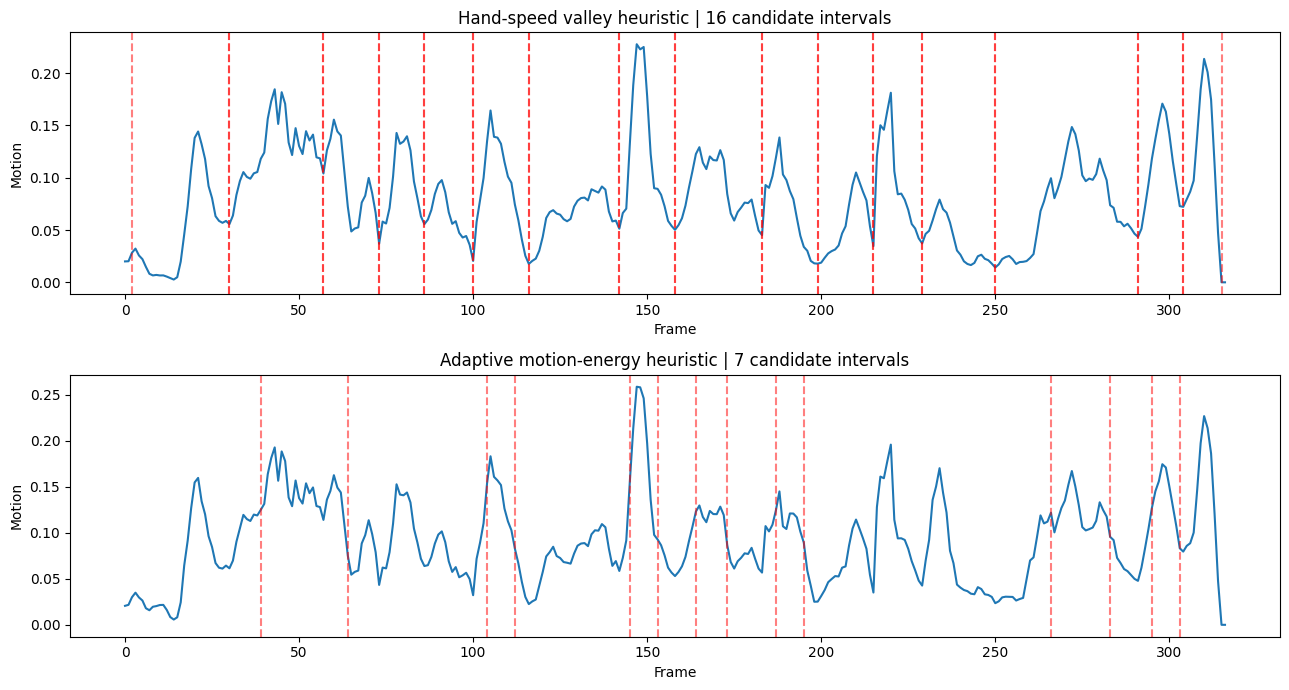

These intervals are motion-activity proposals, not validated word boundaries.


In [78]:
def motion_energy(a):
    speed = np.zeros(len(a), dtype=np.float32)

    for sl in (slice(7, 28), slice(28, 49)):
        hand = a[:, sl]
        visible = landmark_present(hand)

        for i in range(1, len(a)):
            valid = visible[i] & visible[i - 1]

            if valid.any():
                delta = hand[i][valid] - hand[i - 1][valid]
                speed[i] = max(
                    speed[i],
                    np.mean(np.linalg.norm(delta, axis=1))
                )

    return speed


def hand_speed(a):
    speed = np.zeros(len(a), np.float32)

    for sl in (slice(7, 28), slice(28, 49)):
        hand = a[:, sl]
        visible = landmark_present(hand).astype(bool)
        center = np.zeros((len(a), 2), np.float32)

        for i in range(len(a)):
            mask = visible[i]
            if mask.any():
                center[i] = hand[i][mask].mean(axis=0)

        delta = np.linalg.norm(np.diff(center, axis=0), axis=1)
        valid = visible[1:].any(axis=1) & visible[:-1].any(axis=1)
        delta[~valid] = 0
        speed[1:] = np.maximum(speed[1:], delta)

    return speed


def valley_segments(speed, smooth=5, min_distance=10):
    s = uniform_filter1d(speed.astype(np.float32), size=smooth)

    if not np.any(s > 0):
        return [], s

    p90 = np.percentile(s, 90)
    active = np.where(s > 0.15 * p90)[0]

    if len(active) == 0:
        return [], s

    start, end = active[0], active[-1] + 1

    valleys, _ = find_peaks(
        -s[start:end],
        distance=min_distance,
        prominence=0.25 * max(p90, 1e-6)
    )

    cuts = [start] + list(valleys + start) + [end]

    segments = [
        (cuts[i], cuts[i + 1])
        for i in range(len(cuts) - 1)
        if cuts[i + 1] - cuts[i] >= min_distance
    ]

    return segments, s


def adaptive_motion_segments(a, smooth=5, min_duration=8, merge_gap=5):
    raw_energy = np.asarray(motion_energy(a), dtype=np.float32)
    energy = np.nan_to_num(
        raw_energy, nan=0.0, posinf=0.0, neginf=0.0
    )
    energy = uniform_filter1d(energy, size=smooth)

    if not np.any(energy > 0):
        return [], energy

    med = np.median(energy)
    mad = np.median(np.abs(energy - med))
    low = med + 0.25 * mad
    high = med + 1.0 * mad
    active = False
    start = 0
    segments = []

    for i, value in enumerate(energy):
        if not active and value >= high:
            start, active = i, True

        elif active and value < low:
            if i - start >= min_duration:
                segments.append((start, i))
            active = False

    if active and len(energy) - start >= min_duration:
        segments.append((start, len(energy)))

    merged = []

    for s, e in segments:
        if merged and s - merged[-1][1] <= merge_gap:
            merged[-1] = (merged[-1][0], e)
        else:
            merged.append((s, e))

    return merged, energy


seg_rows = []

for uid, a in list(isign_clips.items())[:100]:
    s1, _ = valley_segments(hand_speed(a))
    s2, _ = adaptive_motion_segments(a)

    seg_rows.append({
        "uid": uid,
        "frames": len(a),
        "valley_segments": len(s1),
        "adaptive_segments": len(s2)
    })


segmentation_summary = pd.DataFrame(seg_rows)

display(segmentation_summary.head())
display(
    segmentation_summary[
        ["valley_segments", "adaptive_segments"]
    ].describe()
)


if len(isign_clips):
    seg_uid = next(iter(isign_clips))
    seg_pose = isign_clips[seg_uid]

    valley, speed_smoothed = valley_segments(hand_speed(seg_pose))
    adaptive, energy_smoothed = adaptive_motion_segments(seg_pose)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7))

    for ax, signal, segments, title in [
        (axes[0], speed_smoothed, valley, "Hand-speed valley heuristic"),
        (axes[1], energy_smoothed, adaptive, "Adaptive motion-energy heuristic")
    ]:
        ax.plot(signal)

        for start, end in segments:
            ax.axvline(start, color="red", alpha=0.5, linestyle="--")
            ax.axvline(end, color="red", alpha=0.5, linestyle="--")

        ax.set_title(f"{title} | {len(segments)} candidate intervals")
        ax.set_xlabel("Frame")
        ax.set_ylabel("Motion")

    plt.tight_layout()
    plt.show()


print("These intervals are motion-activity proposals, not validated word boundaries.")

## 12. Save results, models and diagnostics

This section writes the comparison table, dataset audit, split identifiers, model weights and experiment configuration to Drive.

In [75]:
# Save dataset diagnostics.
dataset_audit = {
    "isign_metadata_rows": int(len(isign_meta)),
    "isign_cached_unique_clips": int(len(isign_clips)),
    "isign_word_metadata_recordings": int(len(word_meta)),
    "isign_word_metadata_unique_labels": int(word_meta.label.nunique()),
    "isign_word_pose_recordings": int(len(word_pose)),
    "isign_word_pose_unique_labels": int(available_word_meta.label.nunique()),
    "isign_word_missing_pose_recordings": int(len(missing_word_ids)),
    "isign_sentence_metadata_recordings": int(len(sentence_meta)),
    "isign_sentence_pose_recordings": int(len(sentence_pose_ids)),
    "isign_word_min_frames": int(word_lengths.min()),
    "isign_word_max_frames": int(word_lengths.max()),
    "isign_word_mean_frames": float(word_lengths.mean()),
    "cislr_vocabulary": int(P.gloss.nunique()),
    "cislr_prototypes": int(len(P)),
    "cislr_queries": int(len(Q)),
    "cislr_dev_queries": int(len(dev_idx)),
    "cislr_heldback_queries": int(len(held_idx))
}

with open(OUTPUT_DIR / "dataset_audit.json", "w") as f:
    json.dump(dataset_audit, f, indent=2)

missing_word_meta.to_csv(
    OUTPUT_DIR / "missing_isign_word_pose_ids.csv", index=False
)
visibility_df.to_csv(
    OUTPUT_DIR / "isign_hand_visibility_by_clip.csv", index=False
)
missing_df.to_csv(
    OUTPUT_DIR / "isign_landmark_missingness.csv", index=False
)
segmentation_summary.to_csv(
    OUTPUT_DIR / "isign_motion_activity_diagnostics.csv", index=False
)
comparison.to_csv(
    OUTPUT_DIR / "cislr_model_comparison.csv", index=False
)

np.savez_compressed(
    OUTPUT_DIR / "cislr_evaluation_split.npz",
    prototype_uids=P.uid.astype(str).to_numpy(),
    query_uids=Q.uid.astype(str).to_numpy(),
    development_indices=dev_idx,
    heldback_indices=held_idx,
    prototype_labels=prototype_labels,
    query_labels=query_labels
)

torch.save(
    {
        "state_dict": isign_model.state_dict(),
        "input_dim": FEATURE_DIM,
        "sequence_length": N_FRAMES,
        "pretraining_dataset": "iSign"
    },
    OUTPUT_DIR / "isign_pretrained_transformer_final.pt"
)

if S_cislr_control is not None:
    torch.save(
        cislr_control_model.state_dict(),
        OUTPUT_DIR / "cislr_control_transformer.pt"
    )

if S_stgcn is not None:
    torch.save(
        stgcn_model.state_dict(),
        OUTPUT_DIR / "cislr_stgcn_control.pt"
    )

config = {
    "project_title": "Pose-Based Indian Sign Language Recognition Using Deep Learning on the iSign Dataset",
    "pretraining_dataset": "iSign",
    "recognition_evaluation_dataset": "CISLR",
    "self_supervised_objective": "NT-Xent instance-level contrastive learning",
    "input_feature_dimension": FEATURE_DIM,
    "sequence_length": N_FRAMES,
    "seed": SEED,
    "pretraining_epochs": PRETRAIN_EPOCHS,
    "pretraining_clip_count": len(isign_train_clips),
    "cislr_vocabulary": int(P.gloss.nunique()),
    "cislr_prototype_count": int(len(P)),
    "cislr_query_count": int(len(Q)),
    "development_fraction_approx": float(len(dev_idx) / len(Q)),
    "heldback_fraction_approx": float(len(held_idx) / len(Q)),
    "heldback_is_not_pristine_blind_test": True,
    "word_boundary_ground_truth_available": False
}
with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("All outputs saved to:", OUTPUT_DIR)
print("Files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

All outputs saved to: /content/drive/MyDrive/isl_project/final_methodology_outputs
Files:
- cislr_control_transformer.pt
- cislr_evaluation_split.npz
- cislr_model_comparison.csv
- cislr_stgcn_control.pt
- dataset_audit.json
- experiment_config.json
- isign_hand_visibility_by_clip.csv
- isign_landmark_missingness.csv
- isign_motion_activity_diagnostics.csv
- isign_pretrained_transformer.pt
- isign_pretrained_transformer_final.pt
- missing_isign_word_pose_ids.csv


## 13. Interpretation and Reporting Checklist

Before preparing the final report, verify the following points.

### A. Dataset and methodology

1. **Dataset roles:** iSign is used for self-supervised representation pretraining, while CISLR is used for downstream isolated-sign recognition evaluation.

2. **iSign word-class limitation:** Do not claim supervised 559-class iSign classification. Although 559 unique labels are present among the available word-pose recordings, almost all labels have only one recording, making conventional supervised train/test evaluation unsuitable.

3. **Missing pose data:** Report 586 word-level metadata recordings, 561 available word-pose sequences and 25 recordings without available pose sequences.

4. **Label count:** Report 559 unique labels among the 561 available word-pose recordings.

5. **Metadata limitation:** The inspected iSign metadata contains `uid` and `text` fields but does not provide word-level start and end timestamps.

6. **Pose representation:** Clearly describe the 102-dimensional feature descriptor, including its hand-visibility indicators, and explain the preprocessing and normalisation applied to the pose sequences.

7. **Segmentation:** Describe hand-speed valley detection and adaptive motion-energy detection as exploratory motion-activity segmentation heuristics, not validated semantic word-boundary detection.

8. **Segmentation thresholds:** Document the smoothing parameters, minimum interval duration, merge gap and adaptive thresholds used in the final experiment. Identify the 100-clip analysis as exploratory if the first 100 recordings were used.

9. **No unsupported boundary scores:** Do not report segmentation precision, recall or F1 without manually annotated ground-truth boundaries.

### B. Recognition evaluation

10. **Evaluation split:** Report the CISLR vocabulary size, prototype count, development query count and held-back query count.

11. **Source separation:** Document the removal of recordings sharing source IDs across prototype and query partitions, as well as the separation between development and held-back query sources.

12. **Recognition metrics:** Report Top-1, Top-5 and Top-10 accuracy, alongside macro Top-1 accuracy to account for differences in class frequency.

13. **Consistent comparison:** Use the same prototype vocabulary and query partitions for every recognition model.

14. **Test-set caveat:** Disclose that earlier exploratory work inspected the full CISLR test set before the current held-back partition was defined. Therefore, the held-back set should not be described as a pristine blind test.

### C. Model interpretation

15. **Pretraining objective:** Explain that NT-Xent contrastive learning uses two augmented views of the same recording. It encourages representation consistency under augmentation but does not directly guarantee same-gloss clustering across different recordings or signers.

16. **Cross-dataset interpretation:** Do not treat iSign sentence text as labels for CISLR gloss classes or imply direct cross-dataset supervised label alignment.

17. **Pretraining comparison:** Clearly distinguish iSign-only self-supervised pretraining from CISLR-only contrastive training. Do not attribute performance differences solely to dataset identity when the amount of pretraining data also differs.

18. **Repeated experiments:** Report mean and standard deviation across random seeds where repeated runs are available. Identify deterministic baselines and single-run experiments separately.

### D. Reproducibility

19. Retain the final configuration, feature definition, random seeds, source-aware split IDs, training parameters and model checkpoints.

20. Keep results from the earlier 100-dimensional feature descriptor and mixed iSign-plus-CISLR pretraining experiments separate from the current 102-dimensional, iSign-only pipeline.

---

### Suggested Project Conclusion

This project investigates pose-based Indian Sign Language processing through self-supervised temporal representation learning on the iSign dataset and cross-dataset isolated-sign recognition evaluation on CISLR. The scarcity of repeated isolated-word recordings in iSign motivates the use of self-supervised pretraining rather than conventional supervised word classification.

The learned pose representations are evaluated through prototype-based recognition on a source-separated CISLR evaluation split. Multiple representation-learning approaches and a handcrafted baseline are compared using Top-k and macro Top-1 accuracy. Additionally, hand-speed and adaptive motion-energy methods are explored to investigate temporal motion activity. Since the available iSign metadata does not contain manually annotated word-level timestamps, these segmentation methods are treated as exploratory heuristics rather than validated semantic word-boundary detectors.

The project therefore examines both the potential and the limitations of pose-based sign representation learning, particularly in the context of limited labelled data, missing landmarks and cross-dataset evaluation.